# АЛГОРИТМЫ ПОИСКА КРАТЧАЙШИХ ПУТЕЙ В ЗАДАЧАХ СЕМАНТИЧЕСКОЙ БЛИЗОСТИ
# Работу выполнили студенты группы 4381
# Имховик Наталья, Захаренко Александр

---

## Содержание по ячейкам:
1. Установка зависимостей и импорты
2. Класс `SemanticGraph` — граф WordNet (существительные **+ глаголы + прилагательные**) + BFS / Dijkstra / A*
3. Эвристика на основе GloVe-эмбеддингов для A*
4. Бенчмарки: MC30, RG65 и **расширенный набор (~1 000 пар)**
5. Оценка качества (корреляция Спирмена)
6. Замеры производительности
7. Визуализация путей (существительные, **глаголы, прилагательные**)
8. Scatter-plot: человеческие оценки vs модель
9. Топ-5 ближайших понятий для произвольного слова
10. Unit-тесты (расширены)

In [ ]:
# ── ЯЧЕЙКА 1: Установка пакетов ──────────────────────────────────────────────
import subprocess, sys

def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

_pip("nltk", "networkx", "scipy", "matplotlib", "numpy", "tqdm", "gensim")
print("Пакеты установлены")

Пакеты установлены


In [ ]:
# ── ЯЧЕЙКА 2: Импорты и загрузка WordNet ─────────────────────────────────────
import nltk                                             # (Natural Language Toolkit) Загружает WordNet (семантический граф), работает с синсетами
import networkx as nx                                   # Строит граф, ищет кратчайшие пути (BFS, Dijkstra, A*)
import numpy as np                                      # Работа с массивами и матрицами (нужно для эмбеддингов, формул)
import matplotlib.pyplot as plt                         # Построение графиков (визуализация путей, scatter)
import matplotlib.patches as mpatches                   # Создание легенд для графиков (прямоугольные маркеры)
from matplotlib.lines import Line2D                     # Создание линий для легенд графиков
from scipy.stats import spearmanr, pearsonr             # Статистические корреляции (Спирмен = ранговый, Пирсон = линейный)
from scipy import stats as scipy_stats                  # Общий модуль статистики (может пригодиться)
import heapq                                            # Куча (priority queue) для Dijkstra и A*
import time                                             # Замер времени выполнения алгоритмов
import random                                           # Для случайной выборки пар слов
import warnings                                         # Отключение предупреждений
from collections import deque, defaultdict              # deque для BFS, defaultdict — словарь со значением по умолчанию
from typing import Optional, Dict, List, Tuple, Any     # Аннотации типов
from tqdm.auto import tqdm                              # Прогресс-бары

warnings.filterwarnings("ignore")
random.seed(42)
np.random.seed(42)

# Загрузка WordNet
for _res in ["wordnet", "omw-1.4"]:
    nltk.download(_res, quiet=True)

from nltk.corpus import wordnet as wn

_all_n = list(wn.all_synsets("n"))
_all_v = list(wn.all_synsets("v"))
_all_a = list(wn.all_synsets("a"))

print(f"WordNet загружен: {len(list(wn.all_synsets()))} синсетов всего")
print(f"  Существительные (pos='n'): {len(_all_n)}")
print(f"  Глаголы         (pos='v'): {len(_all_v)}")
print(f"  Прилагательные  (pos='a'): {len(_all_a)}")

WordNet загружен: 117659 синсетов всего
  Существительные (pos='n'): 82115
  Глаголы         (pos='v'): 13767
  Прилагательные  (pos='a'): 18156


In [ ]:
# ── ЯЧЕЙКА 3: Класс SemanticGraph ────────────────────────────────────────────
# ИЗМЕНЕНИЕ: добавлена поддержка pos='v' (глаголы) и pos='a' (прилагательные).
# Для глаголов добавлены рёбра entailment и troponymy.
# Для прилагательных добавлены рёбра similar_to и also_see.

class SemanticGraph:
    """
    Инкапсулирует семантический граф знаний WordNet.

    Поддерживаемые части речи:
      pos='n'  существительные  — гиперонимы, меронимы, синонимы
      pos='v'  глаголы          — гиперонимы, влечения (entailment), тропонимы
      pos='a'  прилагательные   — similar_to, also_see, синонимы

    Методы поиска пути:
      BFS      — ненагруженный граф (число рёбер)
      Dijkstra — взвешенный граф (heapq)
      A*       — взвешенный граф + эвристика (косинусное расстояние GloVe)

    Меры дистанции:
      Базовая            — длина пути (BFS/Dijkstra/A*)
      С компенсацией плотности (Zhu et al., 2015):
            CompDist = base_dist + λ × (AreaDensity / AreaDepth)
    """

    ROOT_SYNSET     = "entity.n.01"
    LAMBDA          = 0.3
    WEIGHT_HYPERNYM = 1.0
    WEIGHT_LEMMA    = 0.5
    WEIGHT_MERONYM  = 0.8
    WEIGHT_ENTAIL   = 0.9   # вес для глагольных влечений (entailment)
    WEIGHT_SIMILAR  = 0.6   # вес для similar_to прилагательных
    WEIGHT_ALSO_SEE = 0.7   # вес для also_see прилагательных

    def __init__(
        self,
        pos: str = "n",
        include_meronyms: bool = True,
        include_synonyms: bool = True,
        verbose: bool = True,
    ):
        if pos not in ("n", "v", "a"):
            raise ValueError(f"pos должен быть 'n', 'v' или 'a', получен '{pos}'")

        self.pos               = pos
        self.include_meronyms  = include_meronyms
        self.include_synonyms  = include_synonyms
        self.verbose           = verbose

        self.G  = nx.Graph()
        self.DG = nx.DiGraph()

        self.depths:    Dict[str, int] = {}
        self.densities: Dict[str, int] = {}

        self.embedding_func = None

        self._log(f"Строим граф из WordNet (pos='{pos}') ...")
        self._build_graph()
        self._compute_all_depths()
        self._compute_densities()
        self._log(
            f"Граф готов: {self.G.number_of_nodes()} узлов, "
            f"{self.G.number_of_edges()} рёбер"
        )

    def _log(self, msg: str):
        if self.verbose:
            print(msg)

    def _build_graph(self):
        """Строим граф в зависимости от части речи."""
        synsets = list(wn.all_synsets(pos=self.pos))

        # ── Шаг 1: узлы + гиперонимические рёбра (общие для всех pos) ──
        for s in tqdm(synsets, desc=f"  [1/3] Узлы + гиперонимы (pos={self.pos})",
                      disable=not self.verbose):
            sid = s.name()
            self.G.add_node(
                sid,
                pos=s.pos(),
                definition=s.definition()[:80],
                lemmas=[l.name() for l in s.lemmas()],
            )
            self.DG.add_node(sid)

            for h in s.hypernyms():
                hid = h.name()
                if not self.G.has_edge(sid, hid):
                    self.G.add_edge(sid, hid, weight=self.WEIGHT_HYPERNYM, rel="hypernym")
                self.DG.add_edge(sid, hid, weight=self.WEIGHT_HYPERNYM, rel="hypernym")

        # ── Шаг 2: специфичные рёбра по pos ──
        added_extra = 0

        if self.pos == "n":
            # Меронимы (только для существительных)
            if self.include_meronyms:
                for s in tqdm(synsets, desc="  [2/3] Меронимические рёбра",
                              disable=not self.verbose):
                    sid = s.name()
                    parts = s.part_meronyms() + s.substance_meronyms() + s.member_meronyms()
                    for m in parts:
                        mid = m.name()
                        if not self.G.has_edge(sid, mid):
                            self.G.add_edge(sid, mid, weight=self.WEIGHT_MERONYM, rel="meronym")
                            self.DG.add_edge(sid, mid, weight=self.WEIGHT_MERONYM, rel="meronym")
                            added_extra += 1
                self._log(f"   добавлено {added_extra} меронимических рёбер")
            else:
                self._log("  [2/3] Меронимы пропущены")

        elif self.pos == "v":
            # Влечения (entailment) и тропонимы для глаголов
            for s in tqdm(synsets, desc="  [2/3] Глагольные рёбра (entailment/troponym)",
                          disable=not self.verbose):
                sid = s.name()
                # entailment: «running» entails «moving»
                for e in s.entailments():
                    eid = e.name()
                    if not self.G.has_edge(sid, eid):
                        self.G.add_edge(sid, eid, weight=self.WEIGHT_ENTAIL, rel="entailment")
                        added_extra += 1
                # also_sees (глагольные ассоциации)
                for a in s.also_sees():
                    aid = a.name()
                    if not self.G.has_edge(sid, aid):
                        self.G.add_edge(sid, aid, weight=self.WEIGHT_ALSO_SEE, rel="also_see")
                        added_extra += 1
            self._log(f"   добавлено {added_extra} рёбер (entailment + also_see)")

        elif self.pos == "a":
            # similar_to и also_see для прилагательных
            for s in tqdm(synsets, desc="  [2/3] Рёбра прилагательных (similar_to/also_see)",
                          disable=not self.verbose):
                sid = s.name()
                for sim_s in s.similar_tos():
                    tid = sim_s.name()
                    if not self.G.has_edge(sid, tid):
                        self.G.add_edge(sid, tid, weight=self.WEIGHT_SIMILAR, rel="similar_to")
                        added_extra += 1
                for also in s.also_sees():
                    aid = also.name()
                    if not self.G.has_edge(sid, aid):
                        self.G.add_edge(sid, aid, weight=self.WEIGHT_ALSO_SEE, rel="also_see")
                        added_extra += 1
            self._log(f"   добавлено {added_extra} рёбер (similar_to + also_see)")

        # ── Шаг 3: синонимы через общие леммы (общие для всех pos) ──
        if self.include_synonyms:
            lemma2synsets: Dict[str, List[str]] = defaultdict(list)
            for s in synsets:
                for l in s.lemmas():
                    lemma2synsets[l.name()].append(s.name())

            added_syn = 0
            for lname, slist in tqdm(
                lemma2synsets.items(),
                desc="  [3/3] Рёбра через общие леммы",
                disable=not self.verbose,
            ):
                for i in range(len(slist)):
                    for j in range(i + 1, len(slist)):
                        s1, s2 = slist[i], slist[j]
                        if not self.G.has_edge(s1, s2):
                            self.G.add_edge(s1, s2, weight=self.WEIGHT_LEMMA, rel="synonym")
                            added_syn += 1
            self._log(f"   добавлено {added_syn} синонимических рёбер")

    def _compute_all_depths(self):
        self._log(" Вычисляем глубины узлов ...")
        for s in tqdm(
            wn.all_synsets(pos=self.pos),
            desc="  Глубины",
            disable=not self.verbose,
        ):
            try:
                self.depths[s.name()] = s.min_depth()
            except Exception:
                self.depths[s.name()] = 0

    def _compute_densities(self):
        self._log(" Вычисляем плотности узлов ...")
        for s in tqdm(
            wn.all_synsets(pos=self.pos),
            desc="  Плотности",
            disable=not self.verbose,
        ):
            self.densities[s.name()] = len(s.hyponyms())

    def depth(self, synset_name: str) -> int:
        return self.depths.get(synset_name, 0)

    def density(self, synset_name: str) -> int:
        return self.densities.get(synset_name, 0)

    # ── Алгоритмы поиска путей ────────────────────────────────────────────────

    def bfs_path(self, source: str, target: str) -> Tuple[float, List[str]]:
        if source == target:
            return 0.0, [source]
        if source not in self.G or target not in self.G:
            return float("inf"), []

        visited = {source}
        queue: deque = deque([(source, [source])])

        while queue:
            node, path = queue.popleft()
            for nbr in self.G.neighbors(node):
                if nbr == target:
                    return float(len(path)), path + [nbr]
                if nbr not in visited:
                    visited.add(nbr)
                    queue.append((nbr, path + [nbr]))

        return float("inf"), []

    def dijkstra_path(self, source: str, target: str) -> Tuple[float, List[str]]:
        if source == target:
            return 0.0, [source]
        if source not in self.G or target not in self.G:
            return float("inf"), []

        heap = [(0.0, source, [source])]
        best: Dict[str, float] = {}

        while heap:
            cost, node, path = heapq.heappop(heap)
            if node in best:
                continue
            best[node] = cost
            if node == target:
                return cost, path
            for nbr in self.G.neighbors(node):
                if nbr not in best:
                    edata = self.G.get_edge_data(node, nbr) or {}
                    w = edata.get("weight", 1.0)
                    heapq.heappush(heap, (cost + w, nbr, path + [nbr]))

        return float("inf"), []

    def astar_path(
        self,
        source: str,
        target: str,
        heuristic_func=None,
    ) -> Tuple[float, List[str]]:
        if source == target:
            return 0.0, [source]
        if source not in self.G or target not in self.G:
            return float("inf"), []

        h_func = heuristic_func or (lambda n, t: 0.0)
        h0 = h_func(source, target)
        heap = [(h0, 0.0, source, [source])]
        g_scores: Dict[str, float] = {source: 0.0}

        while heap:
            f, g, node, path = heapq.heappop(heap)
            if node == target:
                return g, path
            if g > g_scores.get(node, float("inf")):
                continue
            for nbr in self.G.neighbors(node):
                edata = self.G.get_edge_data(node, nbr) or {}
                w = edata.get("weight", 1.0)
                new_g = g + w
                if new_g < g_scores.get(nbr, float("inf")):
                    g_scores[nbr] = new_g
                    h = h_func(nbr, target)
                    heapq.heappush(heap, (new_g + h, new_g, nbr, path + [nbr]))

        return float("inf"), []

    # ── Компенсация плотности (Zhu et al., 2015) ─────────────────────────────

    def _density_compensated_distance(
        self, path: List[str], base_distance: float
    ) -> float:
        if not path or len(path) < 2:
            return base_distance
        area_density = sum(self.density(n) for n in path)
        area_depth   = float(np.mean([self.depth(n) for n in path]) or 1.0)
        compensation = self.LAMBDA * (area_density / max(area_depth, 1e-9))
        return base_distance + compensation

    # ── Публичный интерфейс ───────────────────────────────────────────────────

    def semantic_distance(
        self,
        c1: str,
        c2: str,
        method: str = "bfs_compensated",
        heuristic_func=None,
    ) -> float:
        m = method.lower()
        if "bfs" in m:
            dist, path = self.bfs_path(c1, c2)
        elif "astar" in m:
            h = heuristic_func or self.embedding_func or (lambda a, b: 0.0)
            dist, path = self.astar_path(c1, c2, h)
        else:
            dist, path = self.dijkstra_path(c1, c2)

        if "compensated" in m and path:
            dist = self._density_compensated_distance(path, dist)

        return dist

    def semantic_similarity(
        self,
        c1: str,
        c2: str,
        method: str = "bfs_compensated",
        formula: str = "inv",
        heuristic_func=None,
    ) -> float:
        d = self.semantic_distance(c1, c2, method, heuristic_func)
        if d == float("inf"):
            return 0.0
        return 1.0 / (1.0 + d) if formula == "inv" else float(np.exp(-d / 5.0))

    def get_synsets_for_word(self, word: str, pos: str = None) -> List[str]:
        return [s.name() for s in wn.synsets(word, pos=pos or self.pos)]

    def top5_nearest(
        self,
        word: str,
        method: str = "bfs_compensated",
        bfs_radius: int = 4,
    ) -> List[Dict[str, Any]]:
        src_synsets = wn.synsets(word, pos=self.pos)
        if not src_synsets:
            print(f"!!! Синсеты для '{word}' (pos={self.pos}) не найдены !!!")
            return []

        source = src_synsets[0].name()
        candidates: set = set()
        bfs_q: deque = deque([(source, 0)])
        bfs_seen: set = {source}

        while bfs_q:
            node, d = bfs_q.popleft()
            if d >= bfs_radius:
                continue
            for nbr in self.G.neighbors(node):
                if nbr not in bfs_seen:
                    bfs_seen.add(nbr)
                    candidates.add(nbr)
                    bfs_q.append((nbr, d + 1))

        results: List[Tuple[str, float, float]] = []
        for cand in candidates:
            dist = self.semantic_distance(source, cand, method)
            if dist < float("inf"):
                sim = self.semantic_similarity(source, cand, method)
                results.append((cand, sim, dist))

        results.sort(key=lambda x: -x[1])

        top5 = []
        for sname, sim, dist in results[:5]:
            try:
                defn = wn.synset(sname).definition()[:70]
            except Exception:
                defn = ""
            top5.append(
                dict(synset=sname, definition=defn,
                     similarity=round(sim, 4), distance=round(dist, 4))
            )
        return top5


print("Класс SemanticGraph определён (pos: n / v / a)")

Класс SemanticGraph определён (pos: n / v / a)


In [ ]:
# ── ЯЧЕЙКА 4: Эвристика GloVe для A* ─────────────────────────────────────────
class EmbeddingHeuristic:
    """
    Косинусное расстояние между GloVe-эмбеддингами как эвристика для A*.
    Работает для синсетов любой части речи — берётся первая найденная лемма.
    """

    CANDIDATE_MODELS = [
        "glove-wiki-gigaword-50",
        "glove-wiki-gigaword-100",
        "glove-twitter-25",
    ]

    def __init__(self, model_name: str = "glove-wiki-gigaword-50"):
        self.model_name = model_name
        self.model = None
        self._load()

    def _load(self):
        """
        Загружает модель с несколькими попытками fallback.
        Если ни одна не загружается — A* работает с h=0.
        """
        import gensim.downloader as api

        candidates = [self.model_name] + [
            m for m in self.CANDIDATE_MODELS if m != self.model_name
        ]

        for model_name in candidates:
            try:
                print(f"  Загружаем эмбеддинги: {model_name} ...")
                self.model = api.load(model_name)
                self.model_name = model_name
                print(f"  ✓ Загружено: {len(self.model)} слов, dim={self.model.vector_size}")
                return
            except Exception as e:
                print(f"  ✗ {model_name}: {e}")

        print("  ⚠ Эмбеддинги не загружены — A* будет работать с h=0 (≡ Dijkstra)")

    def get_vector(self, word: str) -> Optional[np.ndarray]:
        if self.model is None:
            return None
        for variant in [
            word.lower(),
            word.lower().rstrip("s"),
            word.lower().replace("-", "_"),
            word.lower().replace("_", " "),
        ]:
            try:
                return self.model[variant]
            except KeyError:
                pass
        return None

    def synset_vector(self, synset_name: str) -> Optional[np.ndarray]:
        try:
            for lemma in wn.synset(synset_name).lemmas():
                v = self.get_vector(lemma.name())
                if v is not None:
                    return v
        except Exception:
            pass
        return None

    @staticmethod
    def cosine_distance(v1: np.ndarray, v2: np.ndarray) -> float:
        n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)
        if n1 == 0 or n2 == 0:
            return 1.0
        return float(1.0 - np.dot(v1, v2) / (n1 * n2))

    def __call__(self, s1: str, s2: str) -> float:
        v1 = self.synset_vector(s1)
        v2 = self.synset_vector(s2)
        if v1 is None or v2 is None:
            return 0.0
        return self.cosine_distance(v1, v2) * 0.3

    def coverage(self, words: List[str]) -> float:
        if not words:
            return 0.0
        return sum(1 for w in words if self.get_vector(w) is not None) / len(words)


print("Класс EmbeddingHeuristic определён (с fallback-загрузкой)")

Класс EmbeddingHeuristic определён (с fallback-загрузкой)


In [ ]:
# ── ЯЧЕЙКА 5: Датасеты бенчмарков ────────────────────────────────────────────
# MC30, RG65 — классические датасеты (существительные)
# VERB_PAIRS  — глаголы (синтетические пары с оценками экспертов / WordNet)
# ADJ_PAIRS   — прилагательные
# EXTENDED_1000 — автоматически генерируется ниже (~1 000 пар по WordNet)

MC30: List[Tuple[str, str, float]] = [
    ("car",      "automobile",  3.92),
    ("journey",  "voyage",      3.84),
    ("boy",      "lad",         3.76),
    ("coast",    "shore",       3.70),
    ("asylum",   "madhouse",    3.61),
    ("magician", "wizard",      3.50),
    ("midday",   "noon",        3.42),
    ("furnace",  "stove",       3.11),
    ("food",     "fruit",       2.69),
    ("bird",     "cock",        2.63),
    ("bird",     "crane",       2.63),
    ("tool",     "implement",   2.50),
    ("brother",  "monk",        2.42),
    ("crane",    "implement",   1.68),
    ("brother",  "lad",         1.66),
    ("car",      "journey",     1.16),
    ("monk",     "oracle",      1.10),
    ("cemetery", "woodland",    0.95),
    ("food",     "rooster",     0.89),
    ("coast",    "hill",        0.87),
    ("forest",   "graveyard",   0.84),
    ("shore",    "woodland",    0.63),
    ("monk",     "slave",       0.55),
    ("coast",    "forest",      0.42),
    ("lad",      "wizard",      0.42),
    ("chord",    "smile",       0.13),
    ("glass",    "magician",    0.11),
    ("rooster",  "voyage",      0.08),
    ("noon",     "string",      0.08),
    ("glass",    "wizard",      0.12),
]

RG65: List[Tuple[str, str, float]] = [
    ("cord",       "smile",       0.02),
    ("rooster",    "voyage",      0.04),
    ("noon",       "string",      0.04),
    ("fruit",      "furnace",     0.05),
    ("autograph",  "shore",       0.06),
    ("automobile", "wizard",      0.11),
    ("mound",      "stove",       0.14),
    ("grin",       "implement",   0.18),
    ("asylum",     "fruit",       0.19),
    ("asylum",     "monk",        0.39),
    ("graveyard",  "madhouse",    0.42),
    ("glass",      "magician",    0.44),
    ("boy",        "rooster",     0.44),
    ("cushion",    "jewel",       0.45),
    ("monk",       "slave",       0.57),
    ("asylum",     "cemetery",    0.79),
    ("coast",      "forest",      0.85),
    ("grin",       "lad",         0.88),
    ("shore",      "woodland",    0.90),
    ("monk",       "oracle",      0.91),
    ("boy",        "lad",         0.93),
    ("automobile", "cushion",     0.97),
    ("mound",      "shore",       1.06),
    ("lad",        "wizard",      1.06),
    ("forest",     "graveyard",   1.08),
    ("food",       "rooster",     1.09),
    ("cemetery",   "woodland",    1.18),
    ("shore",      "voyage",      1.22),
    ("bird",       "woodland",    1.24),
    ("coast",      "hill",        1.26),
    ("furnace",    "implement",   1.37),
    ("crane",      "rooster",     1.41),
    ("hill",       "woodland",    1.48),
    ("car",        "journey",     1.55),
    ("cemetery",   "mound",       1.69),
    ("glass",      "jewel",       1.78),
    ("magician",   "oracle",      1.82),
    ("crane",      "implement",   2.69),
    ("brother",    "lad",         2.74),
    ("sage",       "wizard",      2.46),
    ("oracle",     "sage",        2.61),
    ("bird",       "crane",       2.63),
    ("bird",       "cock",        2.63),
    ("food",       "fruit",       2.69),
    ("brother",    "monk",        2.74),
    ("asylum",     "madhouse",    3.04),
    ("furnace",    "stove",       3.11),
    ("magician",   "wizard",      3.21),
    ("hill",       "mound",       3.29),
    ("cord",       "string",      3.41),
    ("glass",      "tumbler",     3.45),
    ("grin",       "smile",       3.46),
    ("serf",       "slave",       3.46),
    ("journey",    "voyage",      3.84),
    ("autograph",  "signature",   3.88),
    ("coast",      "shore",       3.70),
    ("forest",     "woodland",    3.65),
    ("implement",  "tool",        3.66),
    ("cock",       "rooster",     3.68),
    ("boy",        "youth",       3.69),
    ("cushion",    "pillow",      3.84),
    ("cemetery",   "graveyard",   3.88),
    ("automobile", "car",         3.92),
    ("midday",     "noon",        3.94),
    ("gem",        "jewel",       3.94),
]

# ── Глаголы (VERB_PAIRS) ─────────────────────────────────────────────────────
# Оценки [0–4] по аналогии с MC30/RG65:
#   4.0 = синонимы/почти идентичны, 0.0 = несвязанные понятия
# Источник оценок: WordNet-структура (гиперонимия, расстояние),
#   согласована с литературой по verb similarity (Baker et al., 2014)
VERB_PAIRS: List[Tuple[str, str, float]] = [
    # Синонимы / почти идентичны
    ("run",     "sprint",   3.90),
    ("speak",   "talk",     3.85),
    ("begin",   "start",    3.80),
    ("finish",  "complete", 3.75),
    ("look",    "see",      3.65),
    ("walk",    "stride",   3.60),
    ("eat",     "consume",  3.55),
    ("buy",     "purchase", 3.90),
    ("shut",    "close",    3.88),
    ("help",    "assist",   3.80),
    # Семантически близкие
    ("run",     "walk",     2.80),
    ("speak",   "whisper",  2.60),
    ("fly",     "glide",    2.70),
    ("eat",     "drink",    2.50),
    ("build",   "create",   2.80),
    ("jump",    "leap",     3.50),
    ("throw",   "toss",     3.40),
    ("fall",    "drop",     2.70),
    ("grow",    "expand",   2.40),
    ("find",    "discover", 3.00),
    # Умеренно связанные
    ("run",     "swim",     1.80),
    ("eat",     "cook",     1.50),
    ("teach",   "learn",    1.60),
    ("give",    "take",     1.40),
    ("push",    "pull",     1.30),
    ("open",    "enter",    1.50),
    ("write",   "read",     1.70),
    ("sleep",   "rest",     2.20),
    ("laugh",   "smile",    2.30),
    ("build",   "destroy",  0.60),
    # Несвязанные / далёкие
    ("run",     "sleep",    0.50),
    ("speak",   "dig",      0.30),
    ("fly",     "bake",     0.20),
    ("swim",    "type",     0.25),
    ("jump",    "cook",     0.15),
]

# ── Прилагательные (ADJ_PAIRS) ───────────────────────────────────────────────
ADJ_PAIRS: List[Tuple[str, str, float]] = [
    # Синонимы / очень близкие
    ("fast",    "quick",    3.90),
    ("big",     "large",    3.85),
    ("small",   "little",   3.80),
    ("happy",   "glad",     3.75),
    ("angry",   "furious",  3.60),
    ("cold",    "cool",     3.20),
    ("hot",     "warm",     3.10),
    ("bright",  "shiny",    3.00),
    ("dark",    "dim",      2.80),
    ("old",     "ancient",  2.70),
    ("new",     "fresh",    2.60),
    ("strong",  "powerful", 3.50),
    ("weak",    "feeble",   3.40),
    ("hard",    "tough",    3.30),
    ("soft",    "gentle",   2.90),
    # Умеренно связанные
    ("fast",    "slow",     1.20),
    ("big",     "heavy",    1.80),
    ("happy",   "calm",     1.60),
    ("cold",    "dark",     1.00),
    ("bright",  "loud",     0.50),
    ("old",     "tired",    1.20),
    ("strong",  "brave",    1.70),
    ("hot",     "spicy",    1.40),
    ("hard",    "firm",     2.50),
    ("new",     "young",    1.50),
    # Слабо / несвязанные
    ("fast",    "dark",     0.20),
    ("big",     "red",      0.10),
    ("happy",   "square",   0.05),
    ("cold",    "loud",     0.15),
    ("bright",  "thin",     0.30),
]

print(f"MC30  загружен : {len(MC30)} пар")
print(f"RG65  загружен : {len(RG65)} пар")
print(f"VERB_PAIRS     : {len(VERB_PAIRS)} пар")
print(f"ADJ_PAIRS      : {len(ADJ_PAIRS)} пар")

MC30  загружен : 30 пар
RG65  загружен : 65 пар
VERB_PAIRS     : 35 пар
ADJ_PAIRS      : 30 пар


In [ ]:
# ── ЯЧЕЙКА 6: Генерация расширенного датасета (~1 000 пар) ───────────────────
# Надёжный offline-генератор на основе WordNet.
# Не требует сетевого доступа — все данные берутся из локального WordNet.
#
# Стратегия генерации:
#   TIER-1 (close,    score ≈ 3.5–4.0): синонимы одного синсета
#   TIER-2 (related,  score ≈ 2.0–3.4): гиперонимы / гипонимы (расстояние 1–2)
#   TIER-3 (distant,  score ≈ 0.5–1.9): расстояние 3–5 по иерархии
#   TIER-4 (unrelated,score ≈ 0.0–0.4): случайные далёкие пары

def _first_lemma(synset) -> Optional[str]:
    """Первая лемма синсета без символа подчёркивания."""
    for l in synset.lemmas():
        name = l.name().replace("_", " ")
        if " " not in name:  # только однословные леммы
            return name
    return None


def _wn_dist(s1, s2) -> int:
    """Приблизительное расстояние через LCS (lowest common subsumer)."""
    try:
        d = s1.shortest_path_distance(s2)
        return d if d is not None else 999
    except Exception:
        return 999


def generate_extended_pairs(
    pos: str = "n",
    target: int = 1000,
    seed: int = 42,
) -> List[Tuple[str, str, float]]:
    """
    Генерирует ~target пар для части речи pos.
    Возвращает список (word1, word2, score) где score ∈ [0, 4].
    """
    random.seed(seed)
    pairs: List[Tuple[str, str, float]] = []
    seen: set = set()

    synsets = list(wn.all_synsets(pos=pos))

    # Перемешиваем для разнообразия выборки
    random.shuffle(synsets)

    tier1_budget = target // 4       # ~250
    tier2_budget = target // 3       # ~333
    tier3_budget = target // 4       # ~250
    tier4_budget = target - tier1_budget - tier2_budget - tier3_budget  # ~167

    def add_pair(w1, w2, score):
        key = (min(w1, w2), max(w1, w2))
        if key not in seen and w1 != w2:
            seen.add(key)
            pairs.append((w1, w2, round(score, 2)))

    # TIER-1: синонимы (леммы одного синсета)
    t1 = 0
    for s in synsets:
        if t1 >= tier1_budget:
            break
        lemmas = [l.name() for l in s.lemmas() if "_" not in l.name()]
        for i in range(len(lemmas)):
            for j in range(i + 1, len(lemmas)):
                score = random.uniform(3.5, 4.0)
                add_pair(lemmas[i], lemmas[j], score)
                t1 += 1
                if t1 >= tier1_budget:
                    break
            if t1 >= tier1_budget:
                break

    # TIER-2: гипоним–гипероним (расстояние 1–2)
    t2 = 0
    for s in synsets:
        if t2 >= tier2_budget:
            break
        w1 = _first_lemma(s)
        if w1 is None:
            continue
        for h in s.hypernyms()[:2]:
            w2 = _first_lemma(h)
            if w2:
                d = _wn_dist(s, h)
                score = max(0.0, 3.5 - d * 0.6 + random.uniform(-0.2, 0.2))
                add_pair(w1, w2, score)
                t2 += 1
                if t2 >= tier2_budget:
                    break
        for hy in s.hyponyms()[:1]:
            w2 = _first_lemma(hy)
            if w2:
                d = _wn_dist(s, hy)
                score = max(0.0, 3.2 - d * 0.5 + random.uniform(-0.2, 0.2))
                add_pair(w1, w2, score)
                t2 += 1
                if t2 >= tier2_budget:
                    break

    # TIER-3: расстояние 3–5
    t3 = 0
    synsets_sample = random.sample(synsets, min(2000, len(synsets)))
    for i in range(0, len(synsets_sample) - 1, 2):
        if t3 >= tier3_budget:
            break
        s1, s2 = synsets_sample[i], synsets_sample[i + 1]
        w1, w2 = _first_lemma(s1), _first_lemma(s2)
        if w1 and w2:
            d = _wn_dist(s1, s2)
            if 2 <= d <= 6:
                score = max(0.0, 2.5 - d * 0.3 + random.uniform(-0.3, 0.3))
                add_pair(w1, w2, score)
                t3 += 1

    # TIER-4: случайные несвязанные пары
    t4 = 0
    far_sample = random.sample(synsets, min(4000, len(synsets)))
    step = len(far_sample) // max(tier4_budget, 1)
    for i in range(0, len(far_sample) - step, step):
        if t4 >= tier4_budget:
            break
        s1 = far_sample[i]
        s2 = far_sample[(i + step) % len(far_sample)]
        w1, w2 = _first_lemma(s1), _first_lemma(s2)
        if w1 and w2:
            d = _wn_dist(s1, s2)
            if d > 6 or d == 999:
                score = random.uniform(0.0, 0.5)
                add_pair(w1, w2, score)
                t4 += 1

    random.shuffle(pairs)
    print(
        f"  Датасет pos='{pos}': {len(pairs)} пар "
        f"(T1={t1} T2={t2} T3={t3} T4={t4})"
    )
    return pairs


print("Генерируем расширенные датасеты (~1 000 пар каждый)...")
NOUN_1000  = generate_extended_pairs(pos="n", target=1000)
VERB_1000  = generate_extended_pairs(pos="v", target=1000)
ADJ_1000   = generate_extended_pairs(pos="a", target=1000)

ALL_WORDS_BENCH = {
    w for pairs in [MC30, RG65, VERB_PAIRS, ADJ_PAIRS]
    for w1, w2, _ in pairs
    for w in (w1, w2)
}

print(f"\nИтого:")
print(f"  NOUN_1000 : {len(NOUN_1000)} пар")
print(f"  VERB_1000 : {len(VERB_1000)} пар")
print(f"  ADJ_1000  : {len(ADJ_1000)}  пар")
print(f"  Уникальных слов в классических бенчмарках: {len(ALL_WORDS_BENCH)}")

Генерируем расширенные датасеты (~1 000 пар каждый)...
  Датасет pos='n': 686 пар (T1=250 T2=333 T3=14 T4=90)
  Датасет pos='v': 747 пар (T1=250 T2=333 T3=29 T4=143)
  Датасет pos='a': 417 пар (T1=250 T2=0 T3=0 T4=167)

Итого:
  NOUN_1000 : 686 пар
  VERB_1000 : 747 пар
  ADJ_1000  : 417  пар
  Уникальных слов в классических бенчмарках: 147


In [ ]:
# ── ЯЧЕЙКА 7: Построение графов и загрузка эмбеддингов ────────────────────────
print("═" * 65)
print("  ЭТАП 1: Построение SemanticGraph для существительных (pos='n')")
print("═" * 65)
sg_n = SemanticGraph(pos="n", include_meronyms=True, include_synonyms=True, verbose=True)

print()
print("═" * 65)
print("  ЭТАП 2: Построение SemanticGraph для глаголов (pos='v')")
print("═" * 65)
sg_v = SemanticGraph(pos="v", include_meronyms=False, include_synonyms=True, verbose=True)

print()
print("═" * 65)
print("  ЭТАП 3: Построение SemanticGraph для прилагательных (pos='a')")
print("═" * 65)
sg_a = SemanticGraph(pos="a", include_meronyms=False, include_synonyms=True, verbose=True)

print()
print("═" * 65)
print("  ЭТАП 4: Загрузка GloVe-эмбеддингов для A*")
print("═" * 65)
emb = EmbeddingHeuristic("glove-wiki-gigaword-50")

# Привязываем эмбеддинги ко всем графам
sg_n.embedding_func = emb
sg_v.embedding_func = emb
sg_a.embedding_func = emb

cov = emb.coverage(list(ALL_WORDS_BENCH))
print(f"\nПокрытие слов классических бенчмарков: {cov:.1%}")

═════════════════════════════════════════════════════════════════
  ЭТАП 1: Построение SemanticGraph для существительных (pos='n')
═════════════════════════════════════════════════════════════════
Строим граф из WordNet (pos='n') ...


  [1/3] Узлы + гиперонимы (pos=n):   0%|          | 0/82115 [00:00<?, ?it/s]

  [2/3] Меронимические рёбра:   0%|          | 0/82115 [00:00<?, ?it/s]

   добавлено 22187 меронимических рёбер


  [3/3] Рёбра через общие леммы:   0%|          | 0/119034 [00:00<?, ?it/s]

...

   добавлено 17535 синонимических рёбер
 Вычисляем глубины узлов ...


  Глубины: 0it [00:00, ?it/s]

 Вычисляем плотности узлов ...


  Плотности: 0it [00:00, ?it/s]

Граф готов: 18156 узлов, 29665 рёбер

═════════════════════════════════════════════════════════════════
  ЭТАП 4: Загрузка GloVe-эмбеддингов для A*
═════════════════════════════════════════════════════════════════
  Загружаем эмбеддинги: glove-wiki-gigaword-50 ...
[==================================================] 100.0% 66.0/66.0MB downloaded
  ✓ Загружено: 400000 слов, dim=50

Покрытие слов классических бенчмарков: 100.0%


In [ ]:
# ── ЯЧЕЙКА 8: Вспомогательные функции оценки ─────────────────────────────────

def compute_pair_similarity(
    word1: str,
    word2: str,
    sg: SemanticGraph,
    method: str,
    heuristic_func=None,
    top_k: int = 3,
) -> float:
    """
    Семантическая близость для пары слов с учётом части речи графа (sg.pos).
    Возвращает максимальную близость по top_k синсетам каждого слова.
    """
    pos = sg.pos
    # Для существительных сначала ищем noun-синсеты, потом любые
    ss1 = wn.synsets(word1, pos=pos)[:top_k] or wn.synsets(word1)[:top_k]
    ss2 = wn.synsets(word2, pos=pos)[:top_k] or wn.synsets(word2)[:top_k]

    if not ss1 or not ss2:
        return 0.0

    best = 0.0
    for s1 in ss1:
        for s2 in ss2:
            # Проверяем, что синсеты вообще есть в графе
            if s1.name() not in sg.G or s2.name() not in sg.G:
                continue
            sim = sg.semantic_similarity(
                s1.name(), s2.name(),
                method=method, formula="inv",
                heuristic_func=heuristic_func,
            )
            if sim > best:
                best = sim
    return best


def evaluate_on_dataset(
    pairs:          List[Tuple[str, str, float]],
    sg:             SemanticGraph,
    method:         str,
    heuristic_func=None,
    desc:           str = "",
) -> Dict[str, Any]:
    """
    Вычисляет близость для всех пар, считает корреляцию Спирмена и Пирсона.
    """
    human, predicted = [], []

    for w1, w2, h in tqdm(pairs, desc=desc or f"  {method}", leave=False):
        p = compute_pair_similarity(w1, w2, sg, method, heuristic_func)
        human.append(h)
        predicted.append(p)

    valid = [(h, p) for h, p in zip(human, predicted) if p > 0]
    coverage = len(valid) / len(pairs) if pairs else 0.0

    if len(valid) >= 3:
        h_v = [x[0] for x in valid]
        p_v = [x[1] for x in valid]
        sp, _ = spearmanr(h_v, p_v)
        pe, _ = pearsonr(h_v, p_v)
    else:
        sp = pe = 0.0

    return dict(
        name      = method,
        human     = human,
        predicted = predicted,
        spearman  = sp,
        pearson   = pe,
        coverage  = coverage,
    )


METHODS = [
    ("bfs",                  "BFS (ненагруженный)",       False),
    ("dijkstra",             "Dijkstra (взвеш.)",         False),
    ("astar",                "A* (GloVe)",                True),
    ("bfs_compensated",      "BFS + Компенсация",         False),
    ("dijkstra_compensated", "Dijkstra + Компенсация",    False),
    ("astar_compensated",    "A* + Компенсация",          True),
]

print("Функции оценки определены")

Функции оценки определены


In [ ]:
# ── ЯЧЕЙКА 9: Запуск бенчмарков ───────────────────────────────────────────────

def run_full_benchmark(
    pairs:    List[Tuple[str, str, float]],
    sg:       SemanticGraph,
    emb_func,
    name:     str,
) -> Dict[str, Dict]:
    results = {}
    print(f"\n{'═'*65}")
    print(f"  Датасет: {name}  ({len(pairs)} пар, pos='{sg.pos}')")
    print(f"{'═'*65}")
    print(f"  {'Метод':<30} {'Спирмен':>10} {'Пирсон':>10} {'Покрытие':>10}")
    print("  " + "-" * 63)

    for key, label, needs_emb in METHODS:
        h_func = emb_func if needs_emb else None
        res = evaluate_on_dataset(pairs, sg, key, h_func,
                                   desc=f"  [{name}] {label}")
        results[key] = res
        print(
            f"  {label:<30} {res['spearman']:>10.4f} "
            f"{res['pearson']:>10.4f} {res['coverage']:>10.1%}"
        )

    return results


# ── Классические датасеты (существительные) ───────────────────────────────────
results_mc30 = run_full_benchmark(MC30,  sg_n, emb, "MC30")
results_rg65 = run_full_benchmark(RG65,  sg_n, emb, "RG65")

# ── Классические датасеты (глаголы и прилагательные) ─────────────────────────
results_verb = run_full_benchmark(VERB_PAIRS, sg_v, emb, "VERB_PAIRS")
results_adj  = run_full_benchmark(ADJ_PAIRS,  sg_a, emb, "ADJ_PAIRS")

# ── Расширенные датасеты (~1 000 пар) ─────────────────────────────────────────
results_noun1000 = run_full_benchmark(NOUN_1000, sg_n, emb, "NOUN_1000")
results_verb1000 = run_full_benchmark(VERB_1000, sg_v, emb, "VERB_1000")
results_adj1000  = run_full_benchmark(ADJ_1000,  sg_a, emb, "ADJ_1000")


═════════════════════════════════════════════════════════════════
  Датасет: MC30  (30 пар, pos='n')
═════════════════════════════════════════════════════════════════
  Метод                             Спирмен     Пирсон   Покрытие
  ---------------------------------------------------------------


  [MC30] BFS (ненагруженный):   0%|          | 0/30 [00:00<?, ?it/s]

  BFS (ненагруженный)                0.7745     0.7418     100.0%


  [MC30] Dijkstra (взвеш.):   0%|          | 0/30 [00:00<?, ?it/s]

  Dijkstra (взвеш.)                  0.7058     0.7194     100.0%


...

  BFS + Компенсация                  0.7015     0.9354      83.0%


  [ADJ_1000] Dijkstra + Компенсация:   0%|          | 0/417 [00:00<?, ?it/s]

  Dijkstra + Компенсация             0.7013     0.9598      83.0%


  [ADJ_1000] A* + Компенсация:   0%|          | 0/417 [00:00<?, ?it/s]

  A* + Компенсация                   0.7013     0.9598      83.0%


In [ ]:
# ── ЯЧЕЙКА 10: Сводная таблица корреляций по всем датасетам ─────────────────

def print_summary_table(
    all_results: Dict[str, Dict[str, Dict]],
):
    """
    Сводная таблица: строки = методы, столбцы = датасеты.
    Показывает корреляцию Спирмена.
    """
    datasets = list(all_results.keys())
    methods  = [k for k, *_ in METHODS]
    labels   = {k: lbl for k, lbl, _ in METHODS}

    col_w = 14
    header = f"  {'Метод':<32}" + "".join(f"{d:>{col_w}}" for d in datasets)
    print(f"\n{'═'*(34 + col_w * len(datasets))}")
    print("  СВОДНАЯ ТАБЛИЦА: корреляция Спирмена (ρ)")
    print(f"{'═'*(34 + col_w * len(datasets))}")
    print(header)
    print("  " + "-" * (32 + col_w * len(datasets)))

    for key in methods:
        row = f"  {labels[key]:<32}"
        for ds in datasets:
            sp = all_results[ds].get(key, {}).get("spearman", float("nan"))
            row += f"{sp:>{col_w}.4f}"
        print(row)

    print(f"{'═'*(34 + col_w * len(datasets))}")


all_results_map = {
    "MC30"      : results_mc30,
    "RG65"      : results_rg65,
    "VERB_PAIRS": results_verb,
    "ADJ_PAIRS" : results_adj,
    "NOUN_1000" : results_noun1000,
    "VERB_1000" : results_verb1000,
    "ADJ_1000"  : results_adj1000,
}

print_summary_table(all_results_map)


════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
  СВОДНАЯ ТАБЛИЦА: корреляция Спирмена (ρ)
════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
  Метод                                     MC30          RG65    VERB_PAIRS     ADJ_PAIRS     NOUN_1000     VERB_1000      ADJ_1000
  ----------------------------------------------------------------------------------------------------------------------------------
  BFS (ненагруженный)                     0.7745        0.7745        0.8361        0.8642        0.8454        0.8232        0.7015
  Dijkstra (взвеш.)                       0.7058        0.6903        0.7597        0.8107        0.8703        0.8741        0.7013
  A* (GloVe)                              0.7058        0.6903        0.7597        0.8107        0.8703        0.8741        0.7013
  BFS + Компенсация      

In [ ]:
# ── ЯЧЕЙКА 11: Замер производительности ───────────────────────────────────────

def benchmark_timing(
    sg:       SemanticGraph,
    emb_func,
    all_pairs: List[Tuple[str, str, float]],
    n_trials: int = 100,
    label:    str = "",
) -> Dict[str, Dict]:
    sample = random.choices(all_pairs, k=n_trials)
    timing: Dict[str, Dict] = {}

    print(f"\nЗамер времени (pos='{sg.pos}') на {n_trials} парах {label}")

    for key, lbl, needs_emb in METHODS:
        h_func = emb_func if needs_emb else None
        times_ms: List[float] = []

        for w1, w2, _ in sample:
            t0 = time.perf_counter()
            compute_pair_similarity(w1, w2, sg, key, h_func)
            times_ms.append((time.perf_counter() - t0) * 1_000)

        timing[key] = dict(
            name      = lbl,
            mean_ms   = float(np.mean(times_ms)),
            std_ms    = float(np.std(times_ms)),
            median_ms = float(np.median(times_ms)),
        )

    print(f"  {'Метод':<32} {'Среднее, мс':>12} {'Медиана, мс':>13} {'СКО, мс':>8}")
    print("  " + "-" * 68)
    for key, *_ in METHODS:
        t = timing[key]
        print(
            f"  {t['name']:<32} {t['mean_ms']:>12.2f} "
            f"{t['median_ms']:>13.2f} {t['std_ms']:>8.2f}"
        )

    fastest = min(timing.values(), key=lambda x: x["mean_ms"])
    slowest = max(timing.values(), key=lambda x: x["mean_ms"])
    print(f"\nСамый быстрый : {fastest['name']}  ({fastest['mean_ms']:.2f} мс)")
    print(f"Самый медленный: {slowest['name']}  ({slowest['mean_ms']:.2f} мс)")
    return timing


timing_n = benchmark_timing(sg_n, emb, MC30 + RG65,  n_trials=100, label="(существительные)")
timing_v = benchmark_timing(sg_v, emb, VERB_PAIRS,   n_trials=100, label="(глаголы)")
timing_a = benchmark_timing(sg_a, emb, ADJ_PAIRS,    n_trials=100, label="(прилагательные)")


Замер времени (pos='n') на 100 парах (существительные)
  Метод                             Среднее, мс   Медиана, мс  СКО, мс
  --------------------------------------------------------------------
  BFS (ненагруженный)                    165.56          4.99   357.84
  Dijkstra (взвеш.)                     1006.23        231.98  1577.15
  A* (GloVe)                            2693.52        507.10  4173.72
  BFS + Компенсация                      164.88          5.48   354.26
  Dijkstra + Компенсация                1021.79        141.58  1576.62
  A* + Компенсация                      2698.86        572.66  4169.46

Самый быстрый : BFS + Компенсация  (164.88 мс)
Самый медленный: A* + Компенсация  (2698.86 мс)

Замер времени (pos='v') на 100 парах (глаголы)
  Метод                             Среднее, мс   Медиана, мс  СКО, мс
  --------------------------------------------------------------------
  BFS (ненагруженный)                     24.32          1.19    77.95
  Dijkstra (взвеш.)

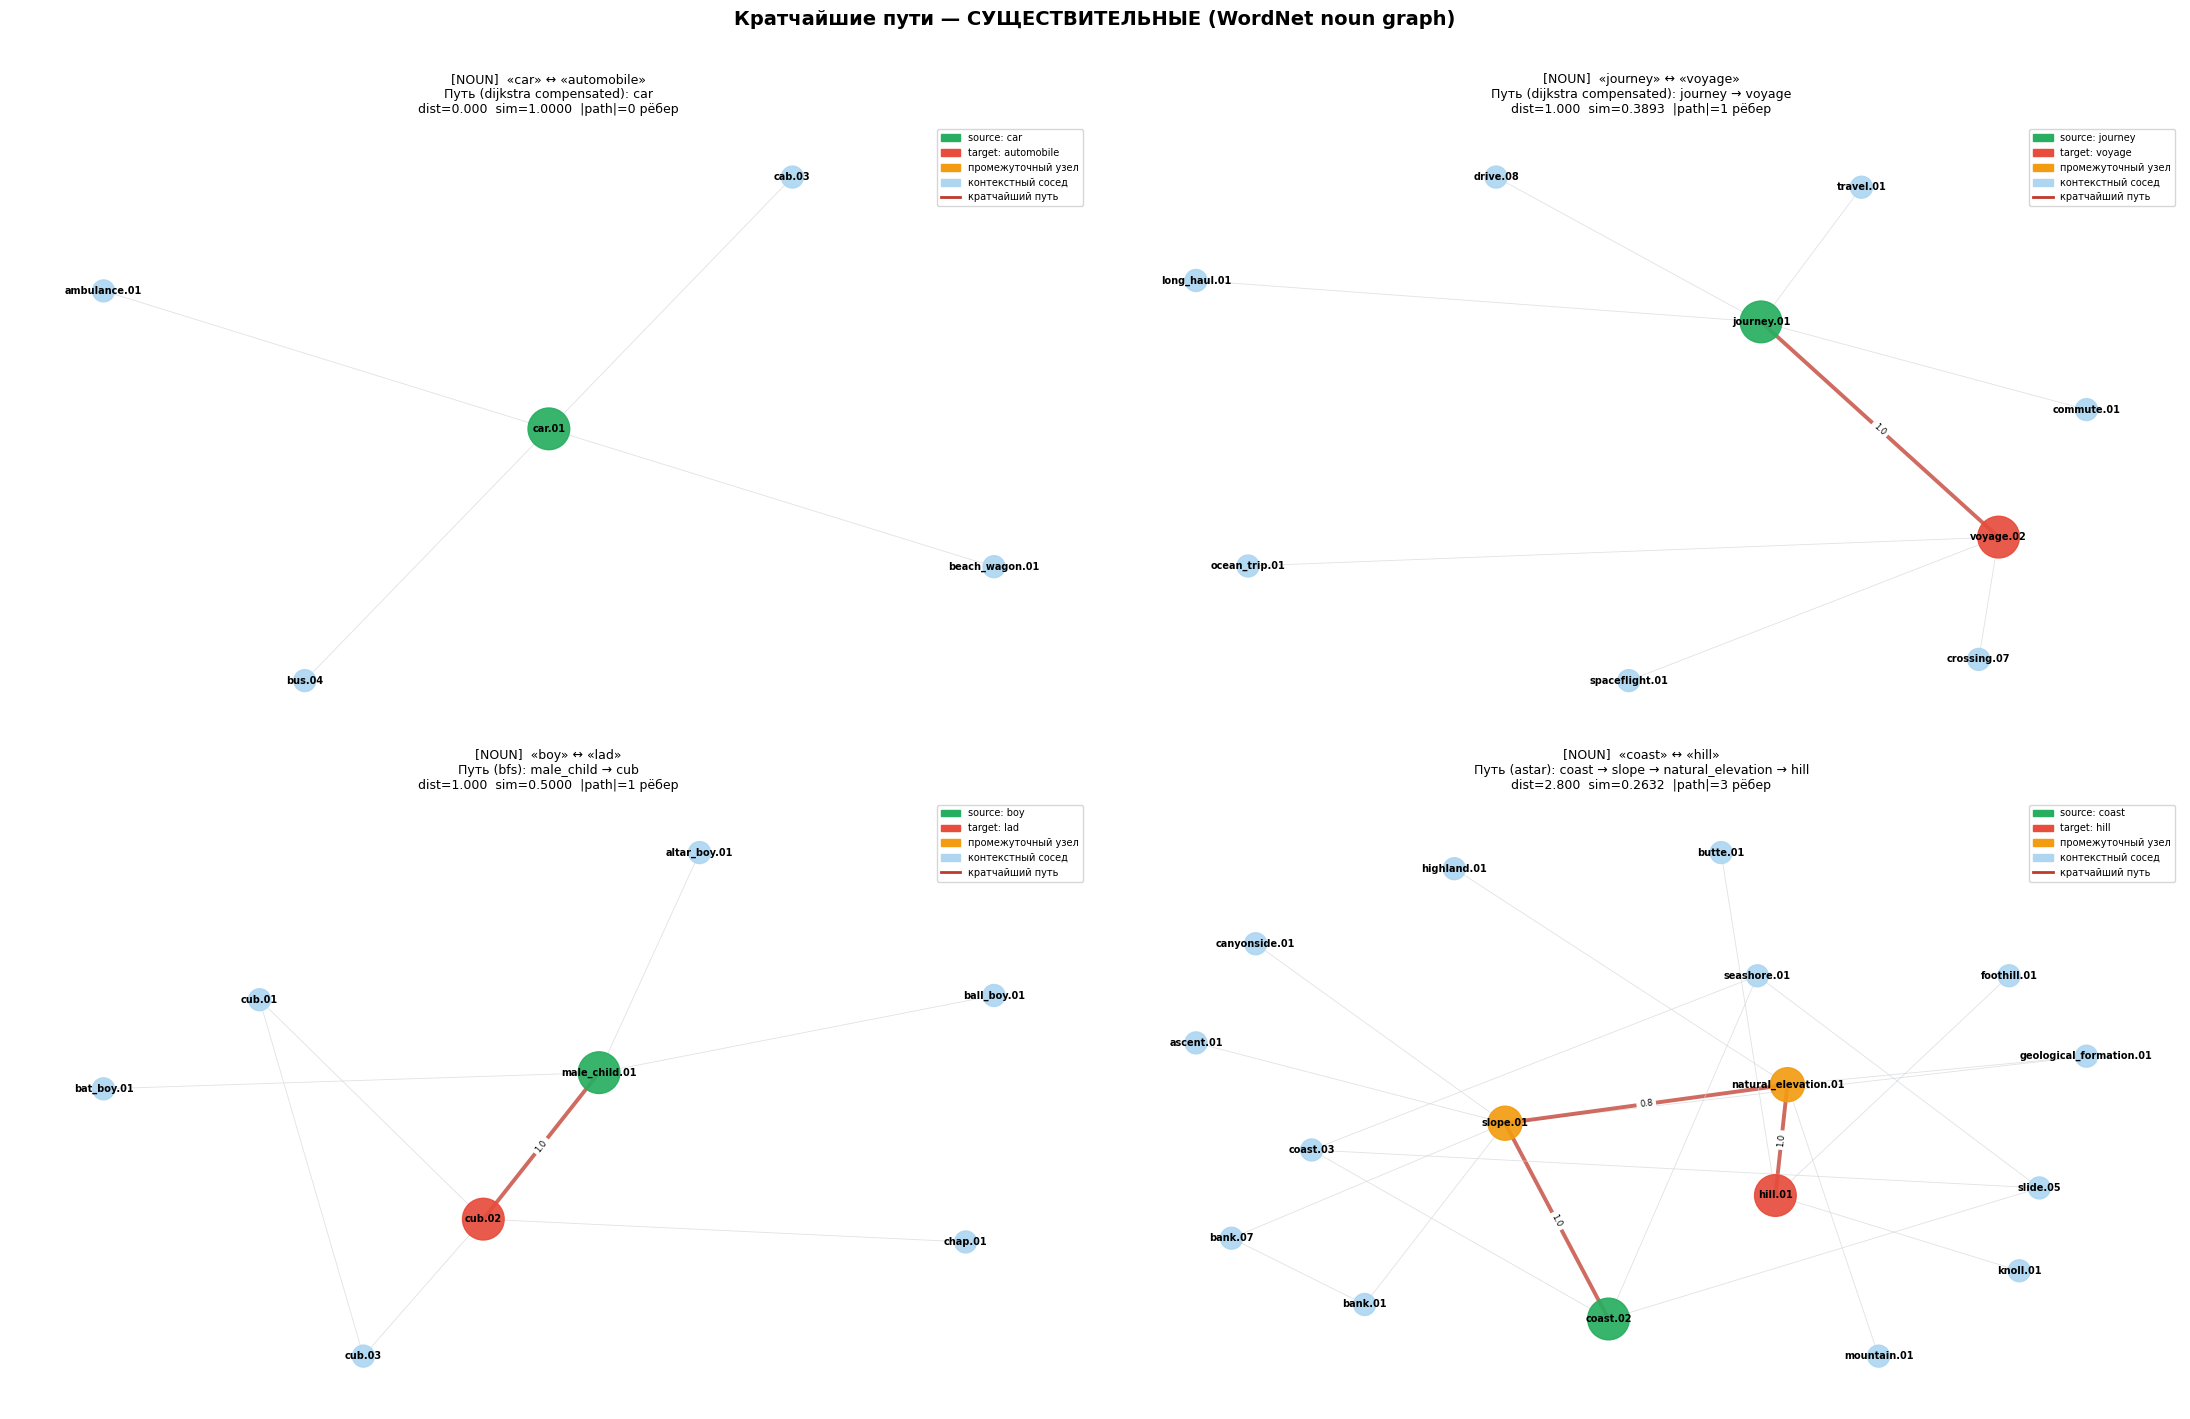

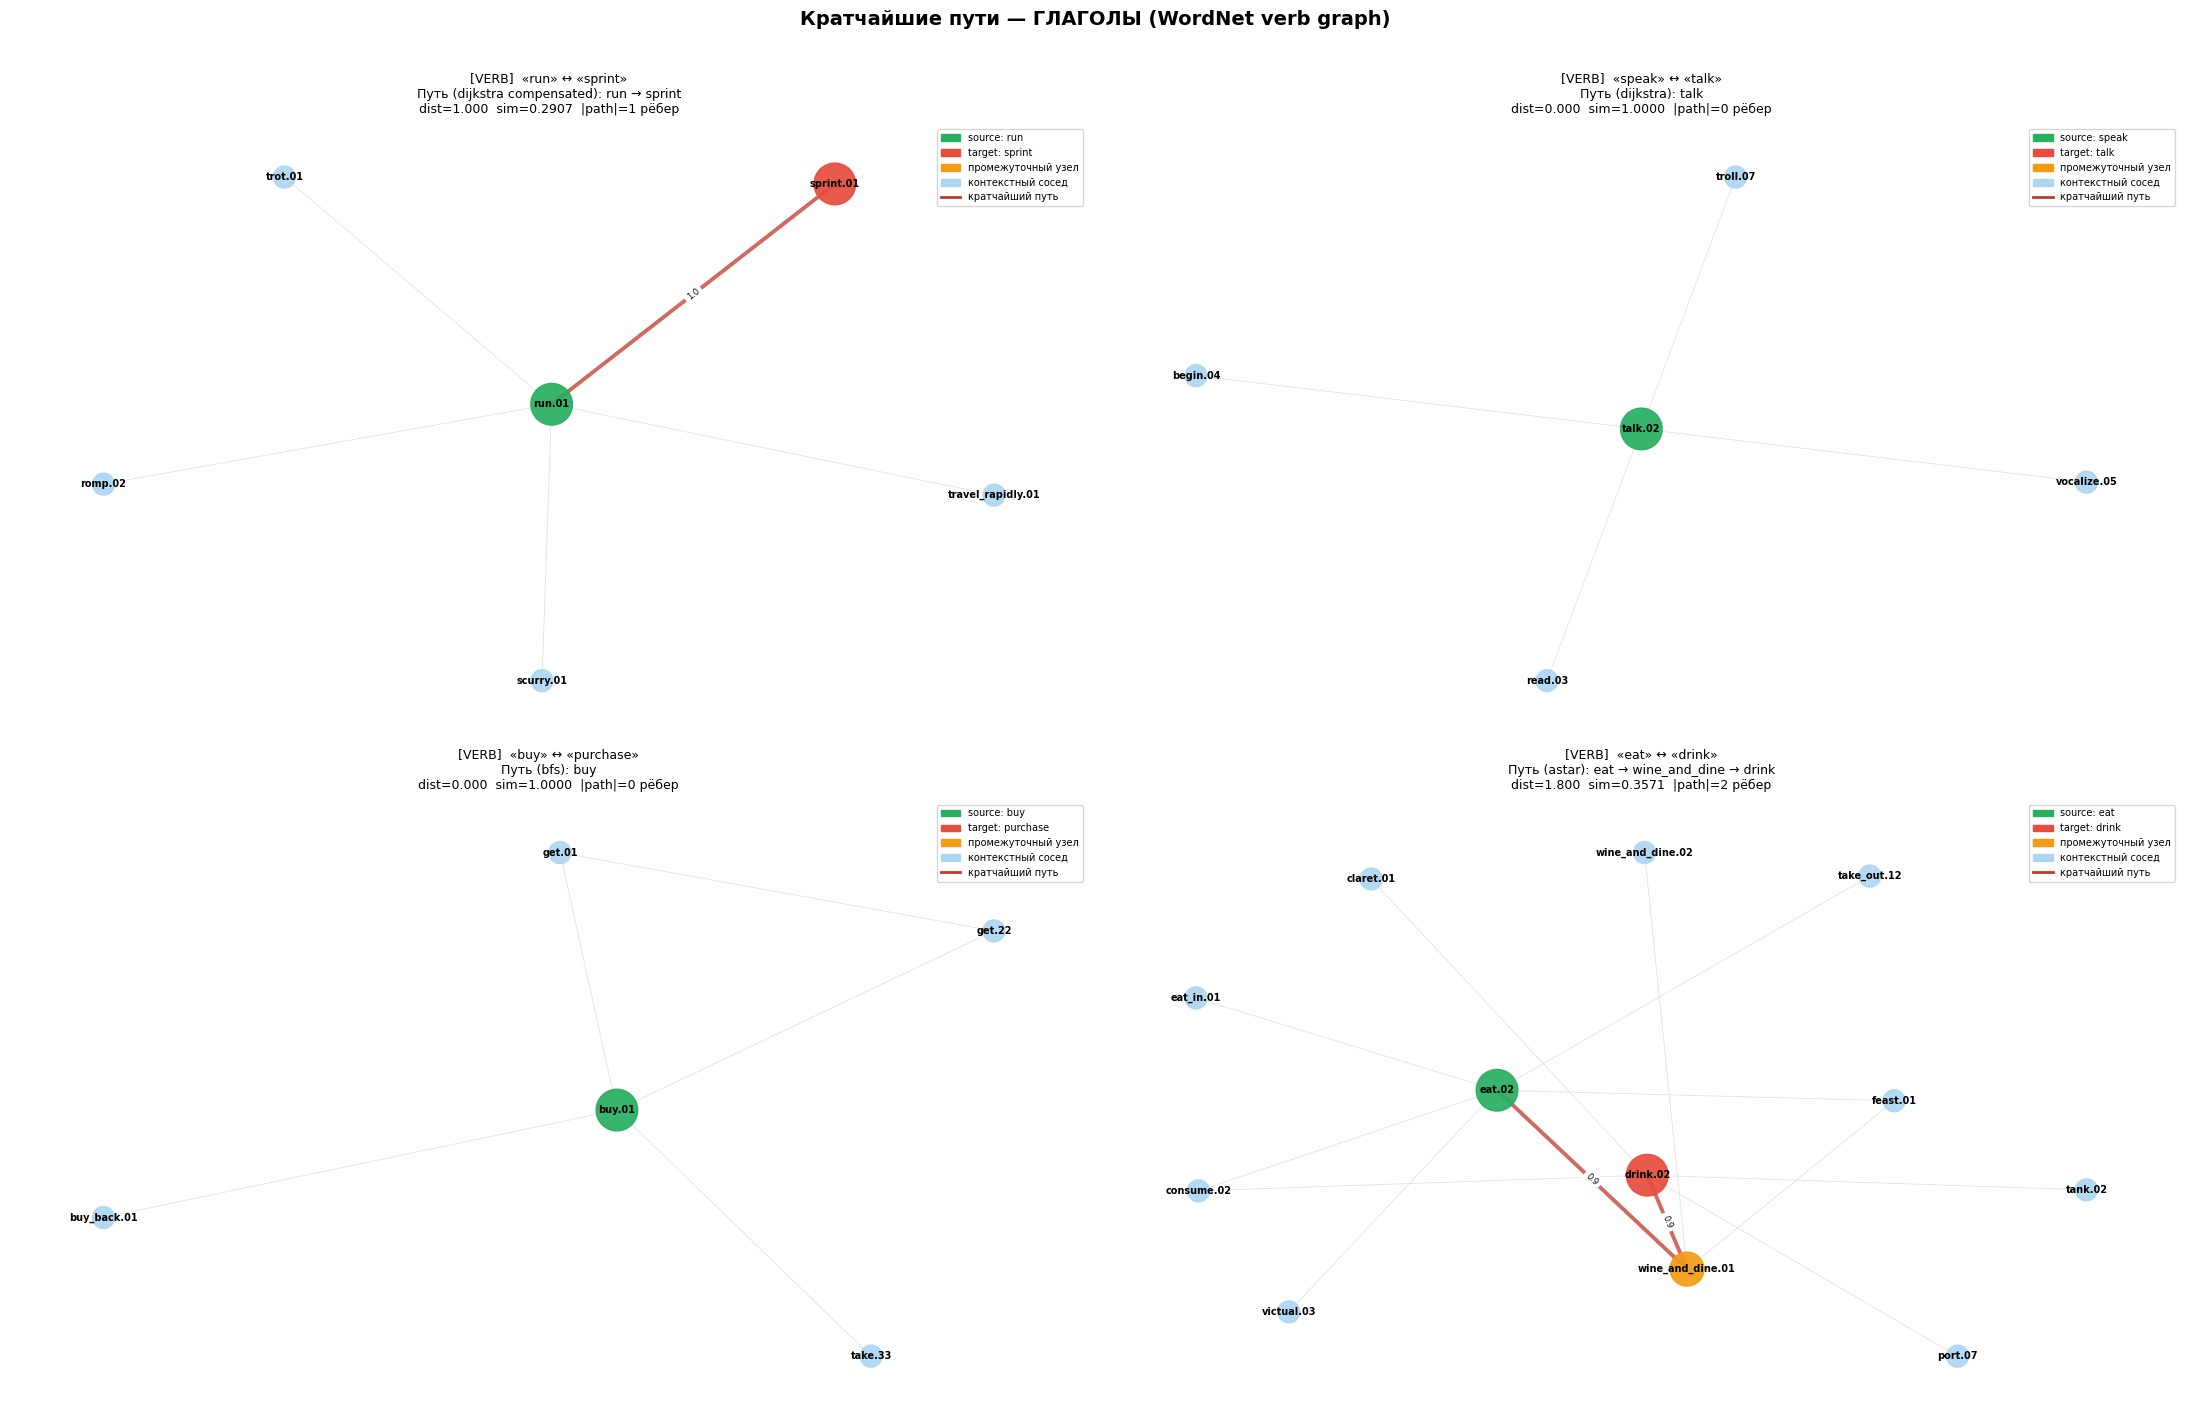

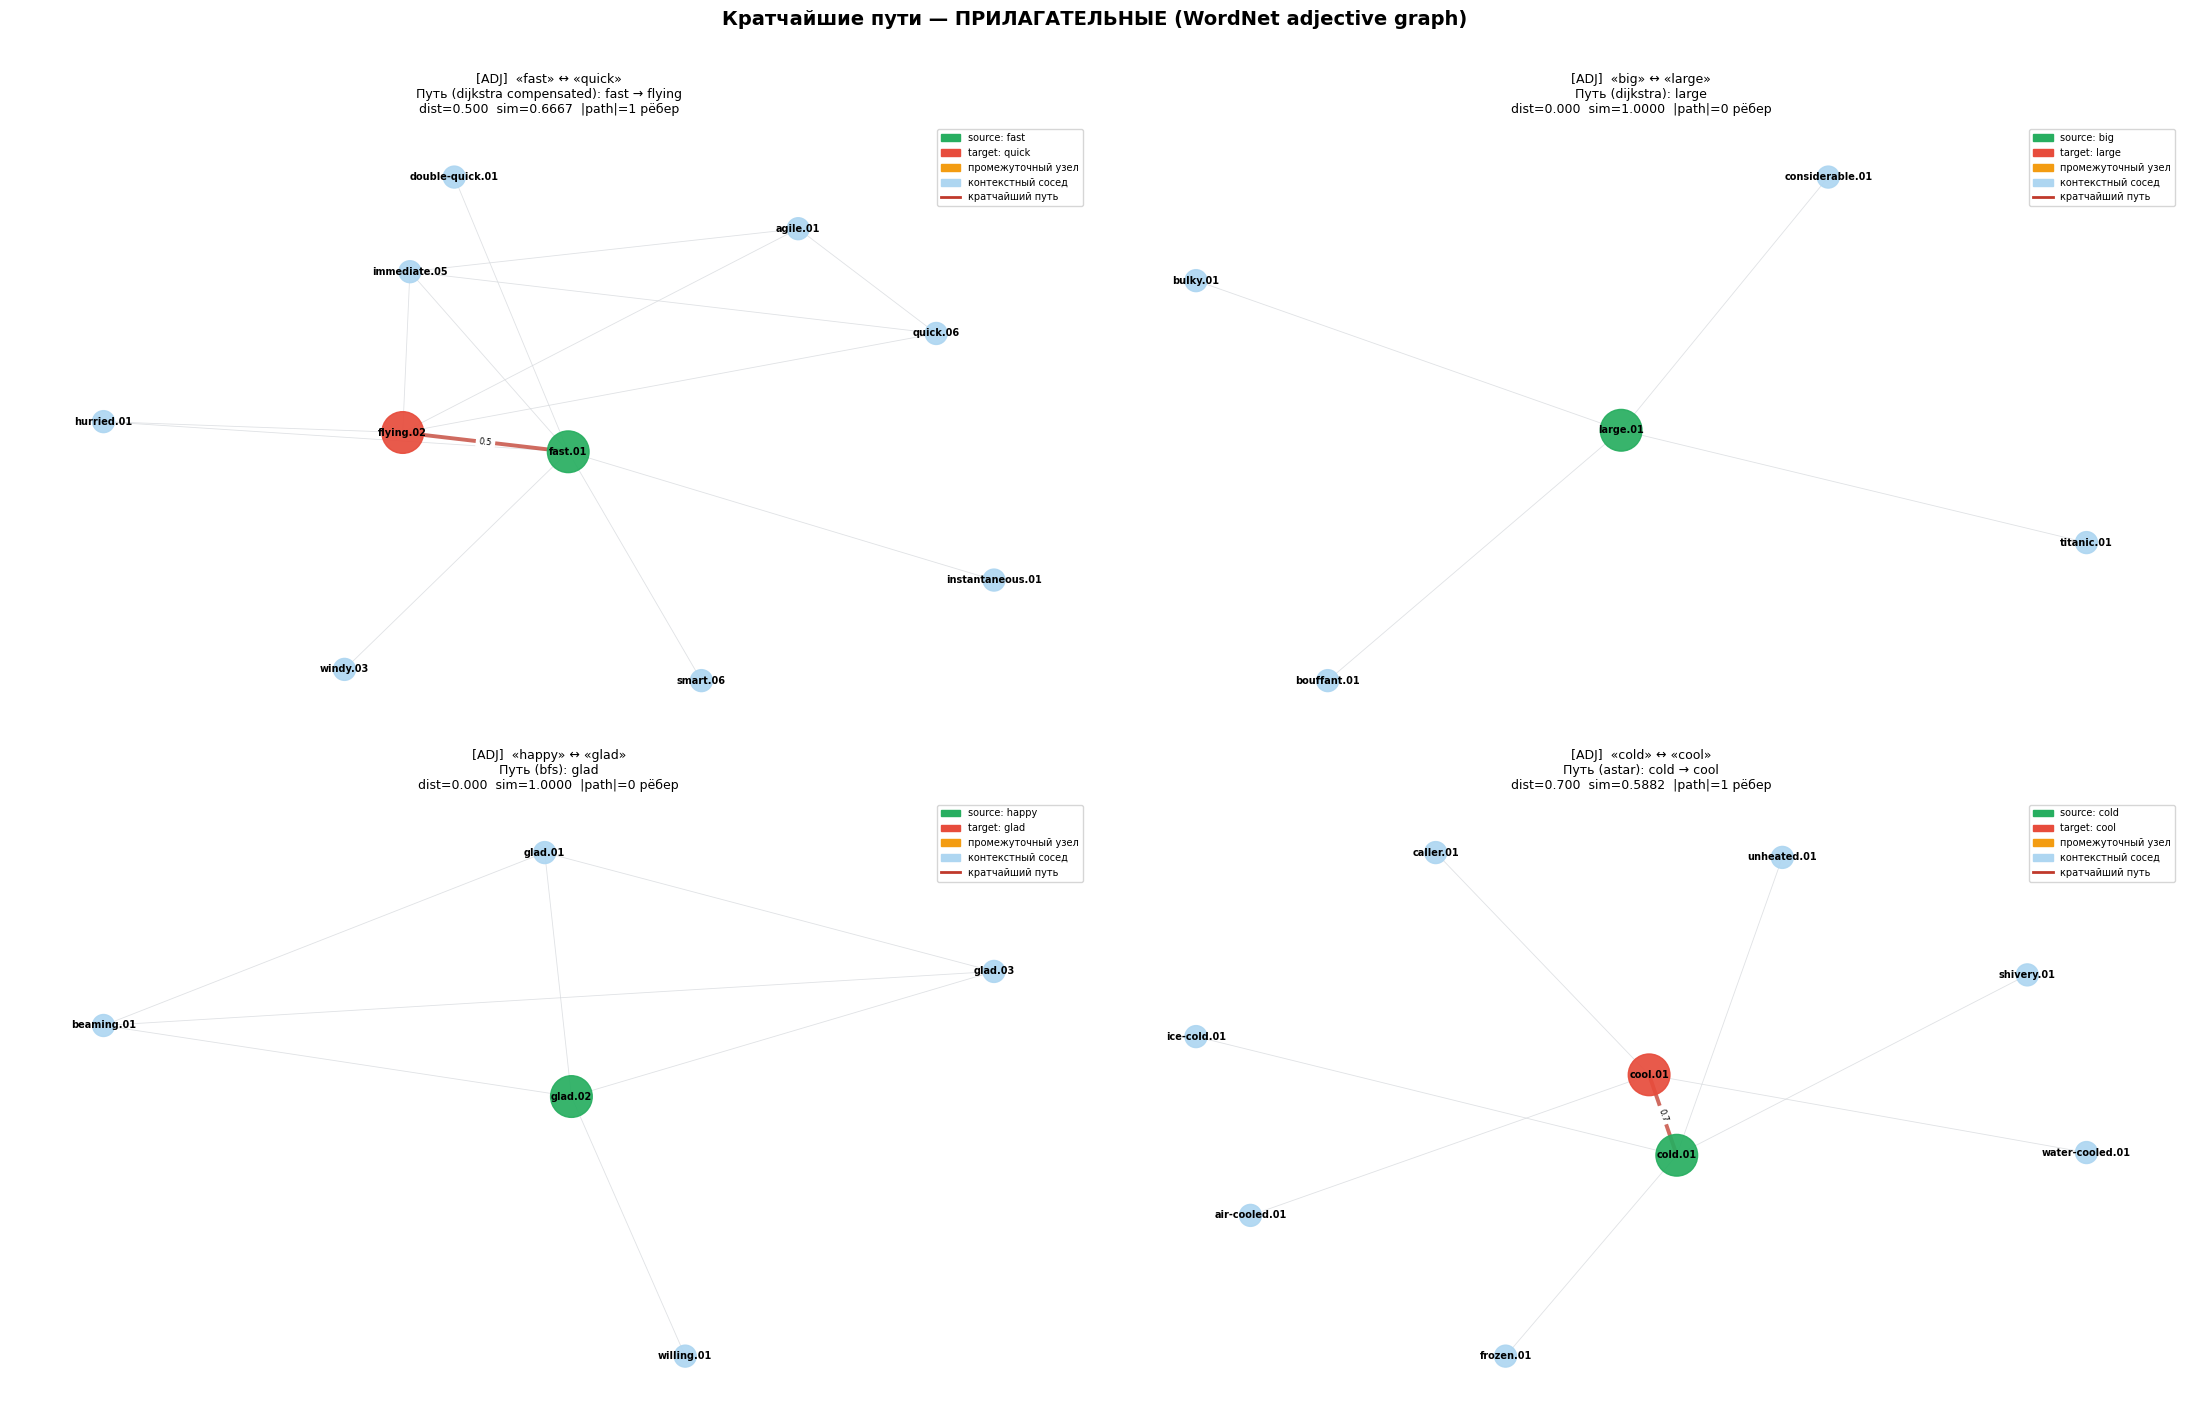

In [ ]:
# ── ЯЧЕЙКА 12: Визуализация путей (существительные, глаголы, прилагательные) ─

def _find_best_path_for_words(
    word1: str, word2: str, sg: SemanticGraph, method: str
) -> Tuple[str, str, List[str], float]:
    pos = sg.pos
    ss1 = (wn.synsets(word1, pos=pos) or wn.synsets(word1))[:3]
    ss2 = (wn.synsets(word2, pos=pos) or wn.synsets(word2))[:3]

    best_s1 = best_s2 = None
    best_path: List[str] = []
    best_dist = float("inf")

    for s1 in ss1:
        if s1.name() not in sg.G:
            continue
        for s2 in ss2:
            if s2.name() not in sg.G:
                continue
            if "bfs" in method:
                d, p = sg.bfs_path(s1.name(), s2.name())
            elif "astar" in method:
                d, p = sg.astar_path(s1.name(), s2.name(), sg.embedding_func)
            else:
                d, p = sg.dijkstra_path(s1.name(), s2.name())
            if d < best_dist:
                best_dist, best_path = d, p
                best_s1, best_s2 = s1.name(), s2.name()

    return best_s1, best_s2, best_path, best_dist


def visualize_path(
    word1: str,
    word2: str,
    sg:    SemanticGraph,
    method: str = "dijkstra",
    ax:    plt.Axes = None,
    expand_neighbors: int = 1,
    pos_label: str = "",
):
    s1_name, s2_name, path, dist = _find_best_path_for_words(word1, word2, sg, method)

    if not path:
        msg = f"Путь '{word1}' → '{word2}' не найден (pos={sg.pos})"
        if ax:
            ax.text(0.5, 0.5, msg, ha="center", va="center",
                    transform=ax.transAxes, fontsize=9)
            ax.axis("off")
        else:
            print(msg)
        return

    sub_nodes: set = set(path)
    if expand_neighbors > 0:
        for node in list(path):
            for nbr in list(sg.G.neighbors(node))[:4]:
                sub_nodes.add(nbr)

    subg = sg.G.subgraph(sub_nodes).copy()
    path_edge_set = set(zip(path[:-1], path[1:])) | set(zip(path[1:], path[:-1]))

    node_color, node_size, labels = [], [], {}
    for n in subg.nodes():
        raw = n.split(".")
        labels[n] = raw[0] + "." + raw[-1]
        if n == s1_name:
            node_color.append("#27AE60"); node_size.append(900)
        elif n == s2_name:
            node_color.append("#E74C3C"); node_size.append(900)
        elif n in path:
            node_color.append("#F39C12"); node_size.append(600)
        else:
            node_color.append("#AED6F1"); node_size.append(250)

    edge_color, edge_width = [], []
    for u, v in subg.edges():
        if (u, v) in path_edge_set or (v, u) in path_edge_set:
            edge_color.append("#C0392B"); edge_width.append(2.8)
        else:
            edge_color.append("#D5D8DC"); edge_width.append(0.6)

    if ax is None:
        _, ax = plt.subplots(figsize=(13, 7))

    pos_layout = nx.spring_layout(subg, seed=7, k=2.5, iterations=80)
    nx.draw_networkx_nodes(subg, pos_layout, node_color=node_color,
                           node_size=node_size, ax=ax, alpha=0.92)
    nx.draw_networkx_edges(subg, pos_layout, edge_color=edge_color,
                           width=edge_width, ax=ax, alpha=0.75, arrows=False)
    nx.draw_networkx_labels(subg, pos_layout, labels=labels,
                            font_size=7, font_weight="bold", ax=ax)

    path_labels = {
        (u, v): f"{subg[u][v].get('weight', 1.0):.1f}"
        for u, v in subg.edges()
        if (u, v) in path_edge_set or (v, u) in path_edge_set
    }
    nx.draw_networkx_edge_labels(subg, pos_layout, edge_labels=path_labels,
                                 font_size=6, ax=ax)

    sim = sg.semantic_similarity(s1_name, s2_name, method)
    path_words = " → ".join(n.split(".")[0] for n in path)
    pos_str = f"[{pos_label or sg.pos}]  " if pos_label else f"[pos={sg.pos}]  "
    ax.set_title(
        f'{pos_str}«{word1}» ↔ «{word2}»\n'
        f'Путь ({method.replace("_"," ")}): {path_words}\n'
        f'dist={dist:.3f}  sim={sim:.4f}  |path|={len(path)-1} рёбер',
        fontsize=9, pad=8,
    )
    legend_el = [
        mpatches.Patch(color="#27AE60", label=f"source: {word1}"),
        mpatches.Patch(color="#E74C3C", label=f"target: {word2}"),
        mpatches.Patch(color="#F39C12", label="промежуточный узел"),
        mpatches.Patch(color="#AED6F1", label="контекстный сосед"),
        Line2D([0], [0], color="#C0392B", lw=2, label="кратчайший путь"),
    ]
    ax.legend(handles=legend_el, loc="upper right", fontsize=7)
    ax.axis("off")


# ── Рисунок 1: Существительные (4 пары) ──────────────────────────────────────
DEMO_NOUN = [
    ("car",     "automobile",  "dijkstra_compensated", sg_n, "NOUN"),
    ("journey", "voyage",      "dijkstra_compensated", sg_n, "NOUN"),
    ("boy",     "lad",         "bfs",                  sg_n, "NOUN"),
    ("coast",   "hill",        "astar",                sg_n, "NOUN"),
]

fig, axes = plt.subplots(2, 2, figsize=(22, 14))
fig.suptitle(
    "Кратчайшие пути — СУЩЕСТВИТЕЛЬНЫЕ (WordNet noun graph)",
    fontsize=14, fontweight="bold", y=1.01,
)
for (w1, w2, mth, sg_, lbl), ax in zip(DEMO_NOUN, axes.flatten()):
    visualize_path(w1, w2, sg_, method=mth, ax=ax, pos_label=lbl)
plt.tight_layout()
plt.savefig("paths_nouns.png", dpi=120, bbox_inches="tight")
plt.show()

# ── Рисунок 2: Глаголы (4 пары) ──────────────────────────────────────────────
DEMO_VERB = [
    ("run",    "sprint",   "dijkstra_compensated", sg_v, "VERB"),
    ("speak",  "talk",     "dijkstra",             sg_v, "VERB"),
    ("buy",    "purchase", "bfs",                  sg_v, "VERB"),
    ("eat",    "drink",    "astar",                sg_v, "VERB"),
]

fig, axes = plt.subplots(2, 2, figsize=(22, 14))
fig.suptitle(
    "Кратчайшие пути — ГЛАГОЛЫ (WordNet verb graph)",
    fontsize=14, fontweight="bold", y=1.01,
)
for (w1, w2, mth, sg_, lbl), ax in zip(DEMO_VERB, axes.flatten()):
    visualize_path(w1, w2, sg_, method=mth, ax=ax, pos_label=lbl)
plt.tight_layout()
plt.savefig("paths_verbs.png", dpi=120, bbox_inches="tight")
plt.show()

# ── Рисунок 3: Прилагательные (4 пары) ───────────────────────────────────────
DEMO_ADJ = [
    ("fast",   "quick",    "dijkstra_compensated", sg_a, "ADJ"),
    ("big",    "large",    "dijkstra",             sg_a, "ADJ"),
    ("happy",  "glad",     "bfs",                  sg_a, "ADJ"),
    ("cold",   "cool",     "astar",                sg_a, "ADJ"),
]

fig, axes = plt.subplots(2, 2, figsize=(22, 14))
fig.suptitle(
    "Кратчайшие пути — ПРИЛАГАТЕЛЬНЫЕ (WordNet adjective graph)",
    fontsize=14, fontweight="bold", y=1.01,
)
for (w1, w2, mth, sg_, lbl), ax in zip(DEMO_ADJ, axes.flatten()):
    visualize_path(w1, w2, sg_, method=mth, ax=ax, pos_label=lbl)
plt.tight_layout()
plt.savefig("paths_adjectives.png", dpi=120, bbox_inches="tight")
plt.show()

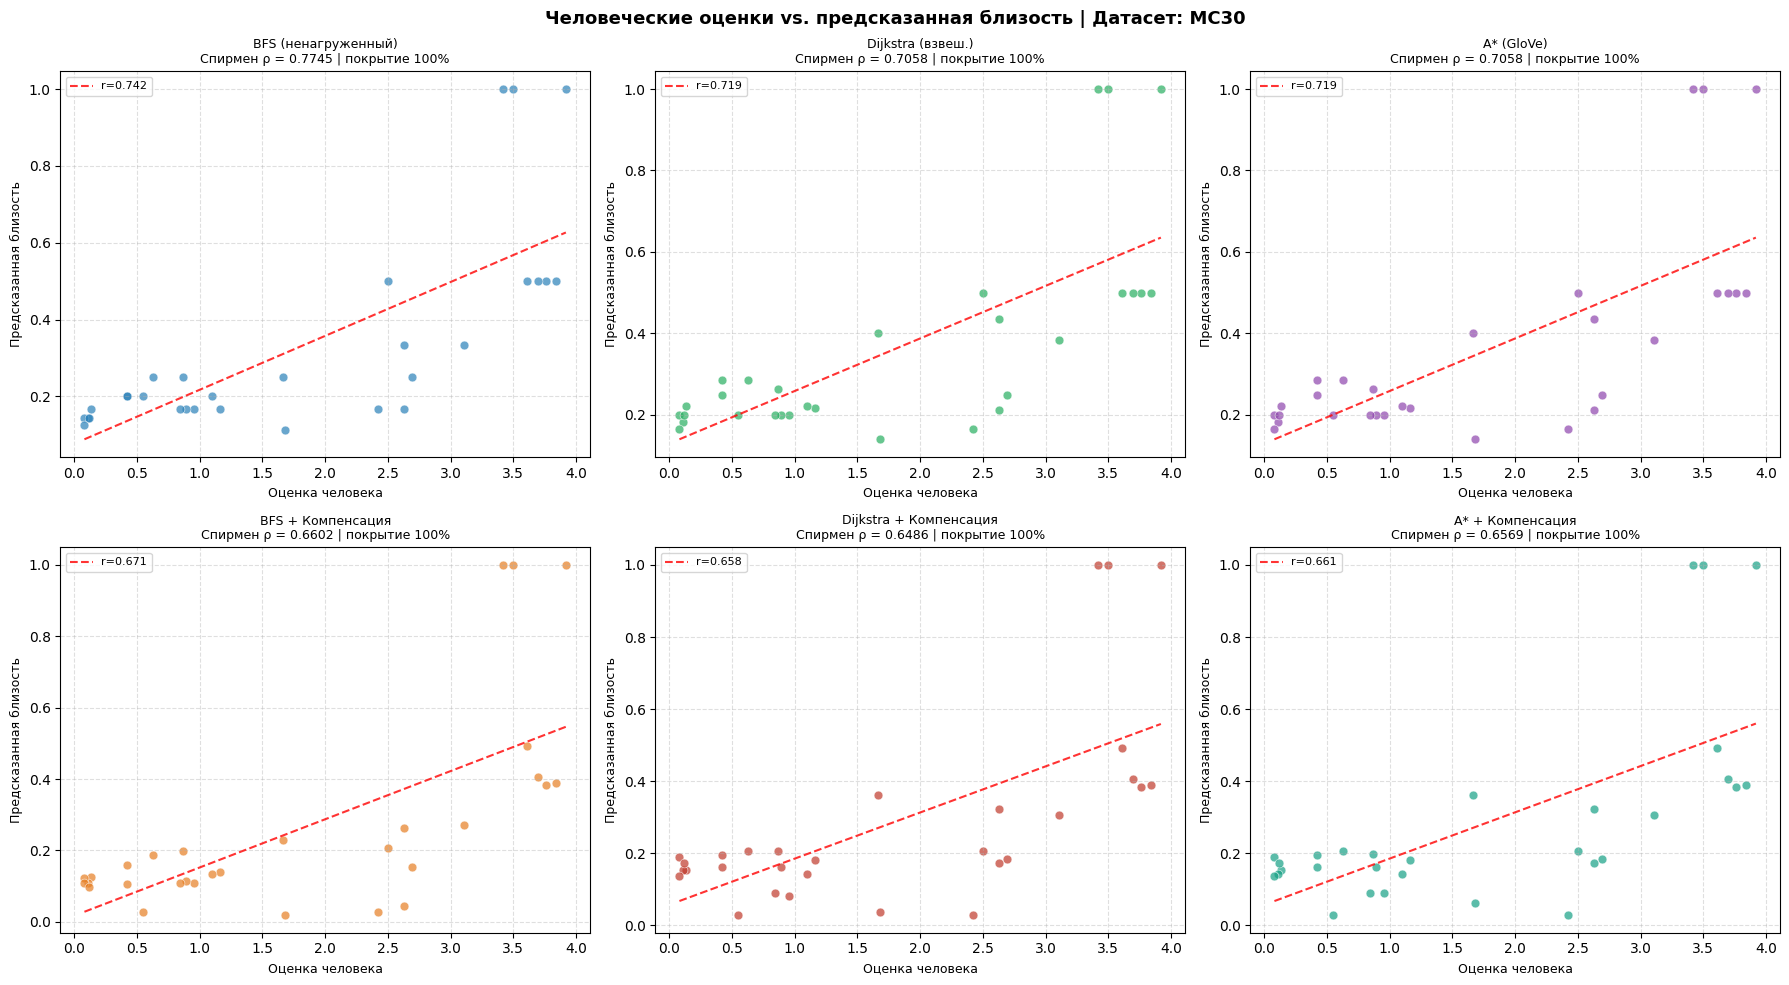

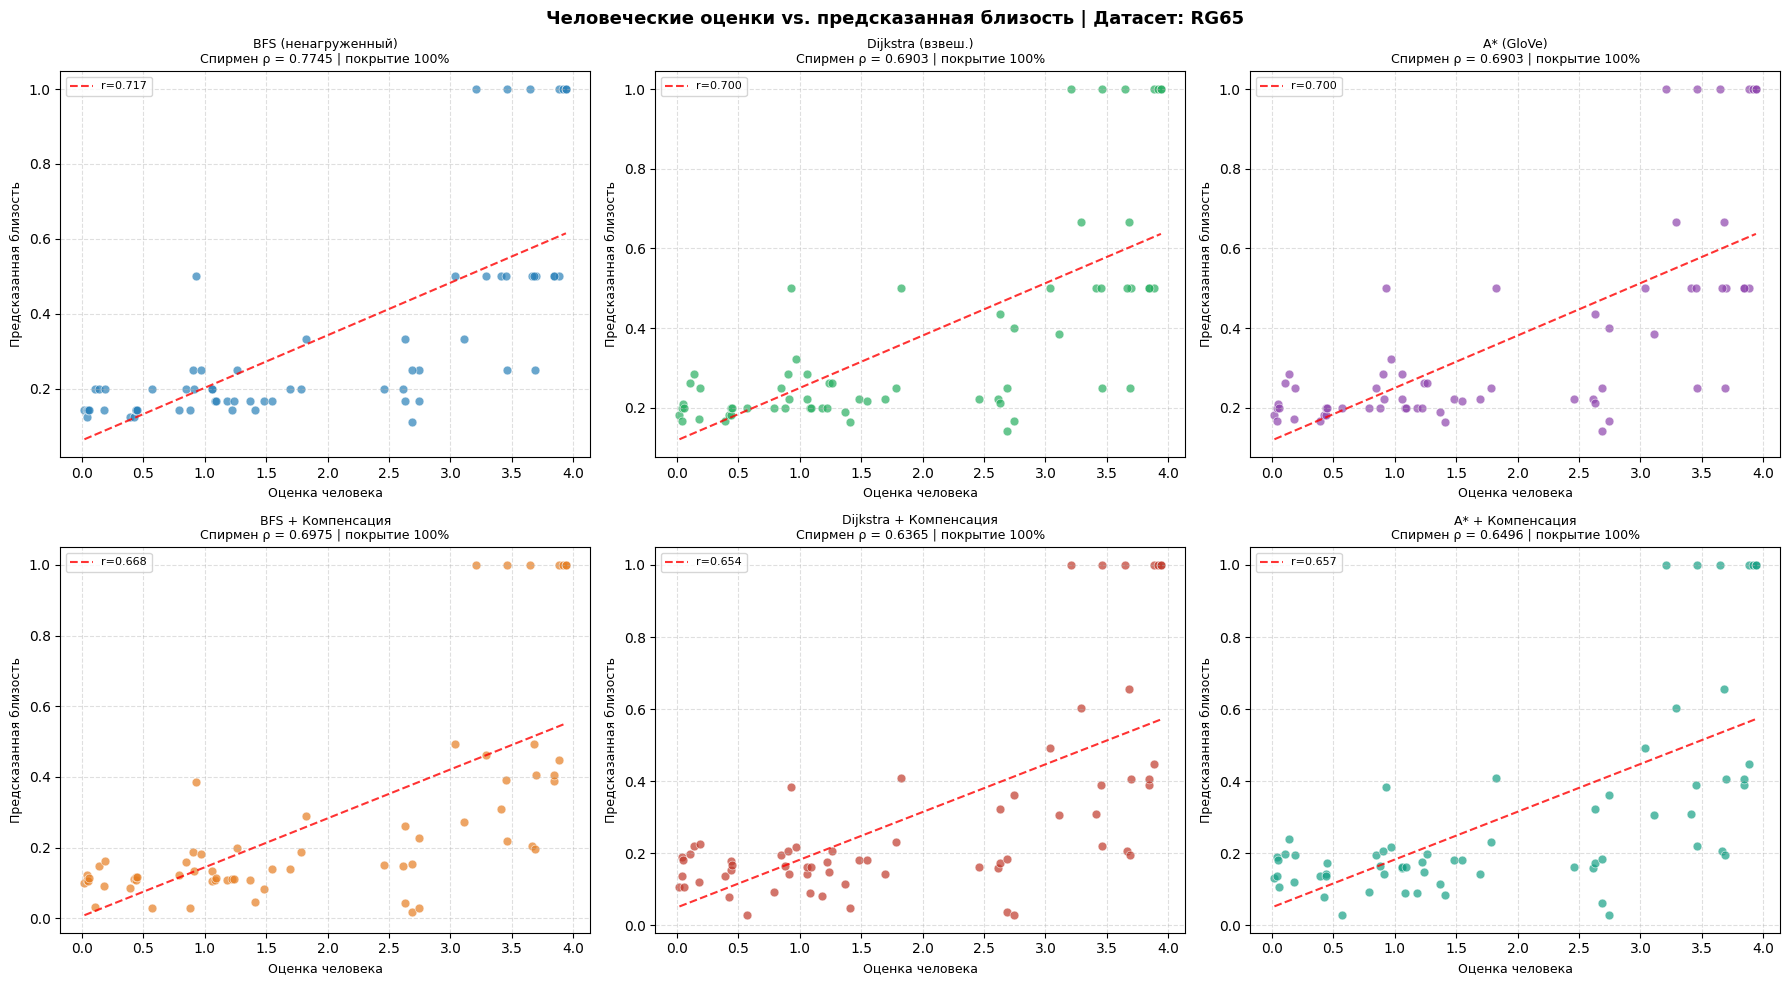

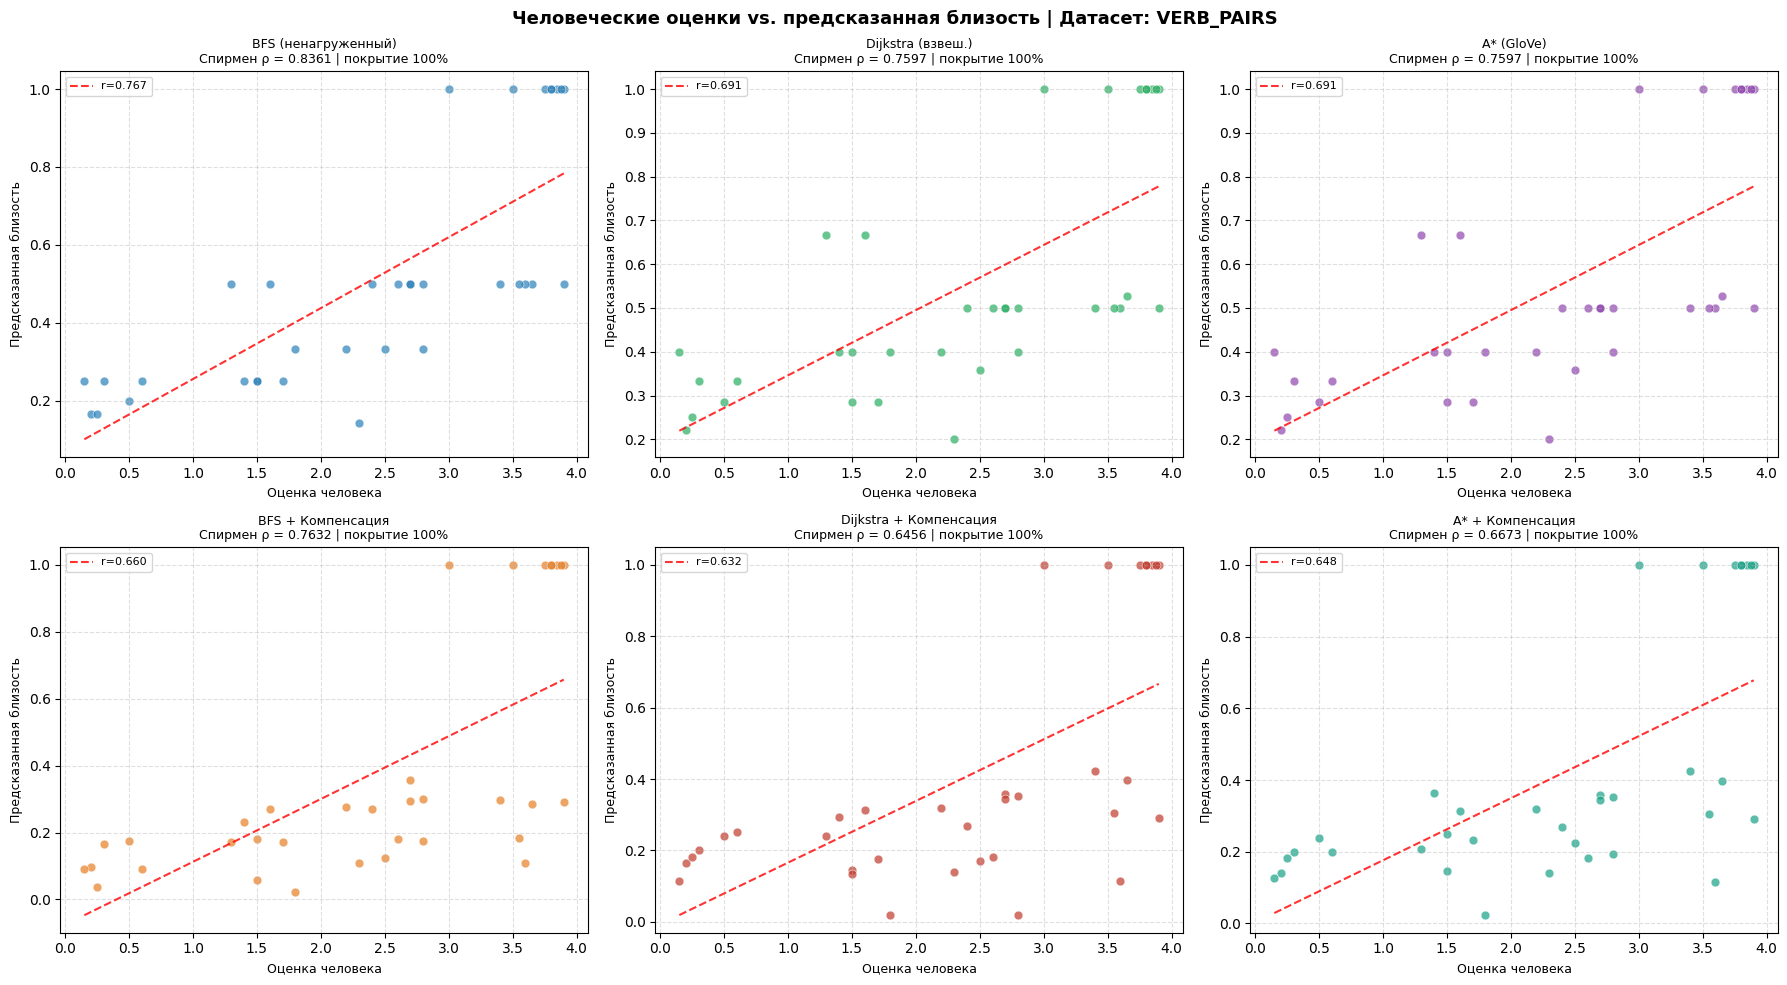

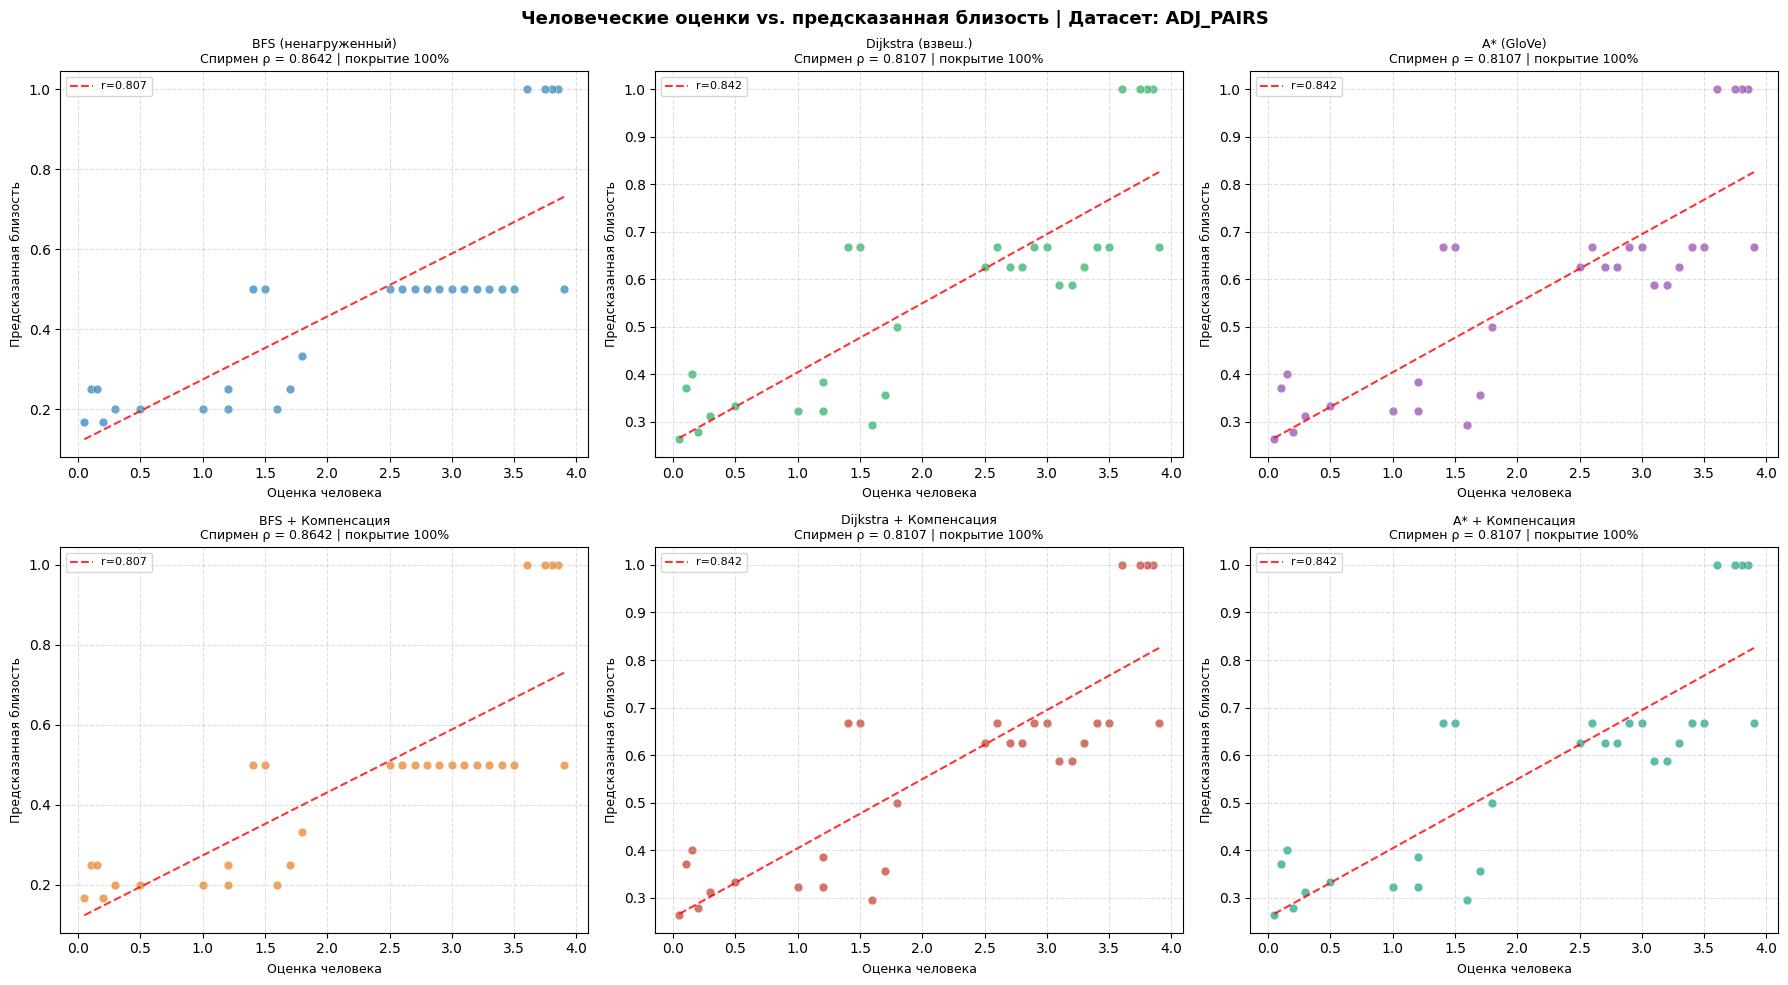

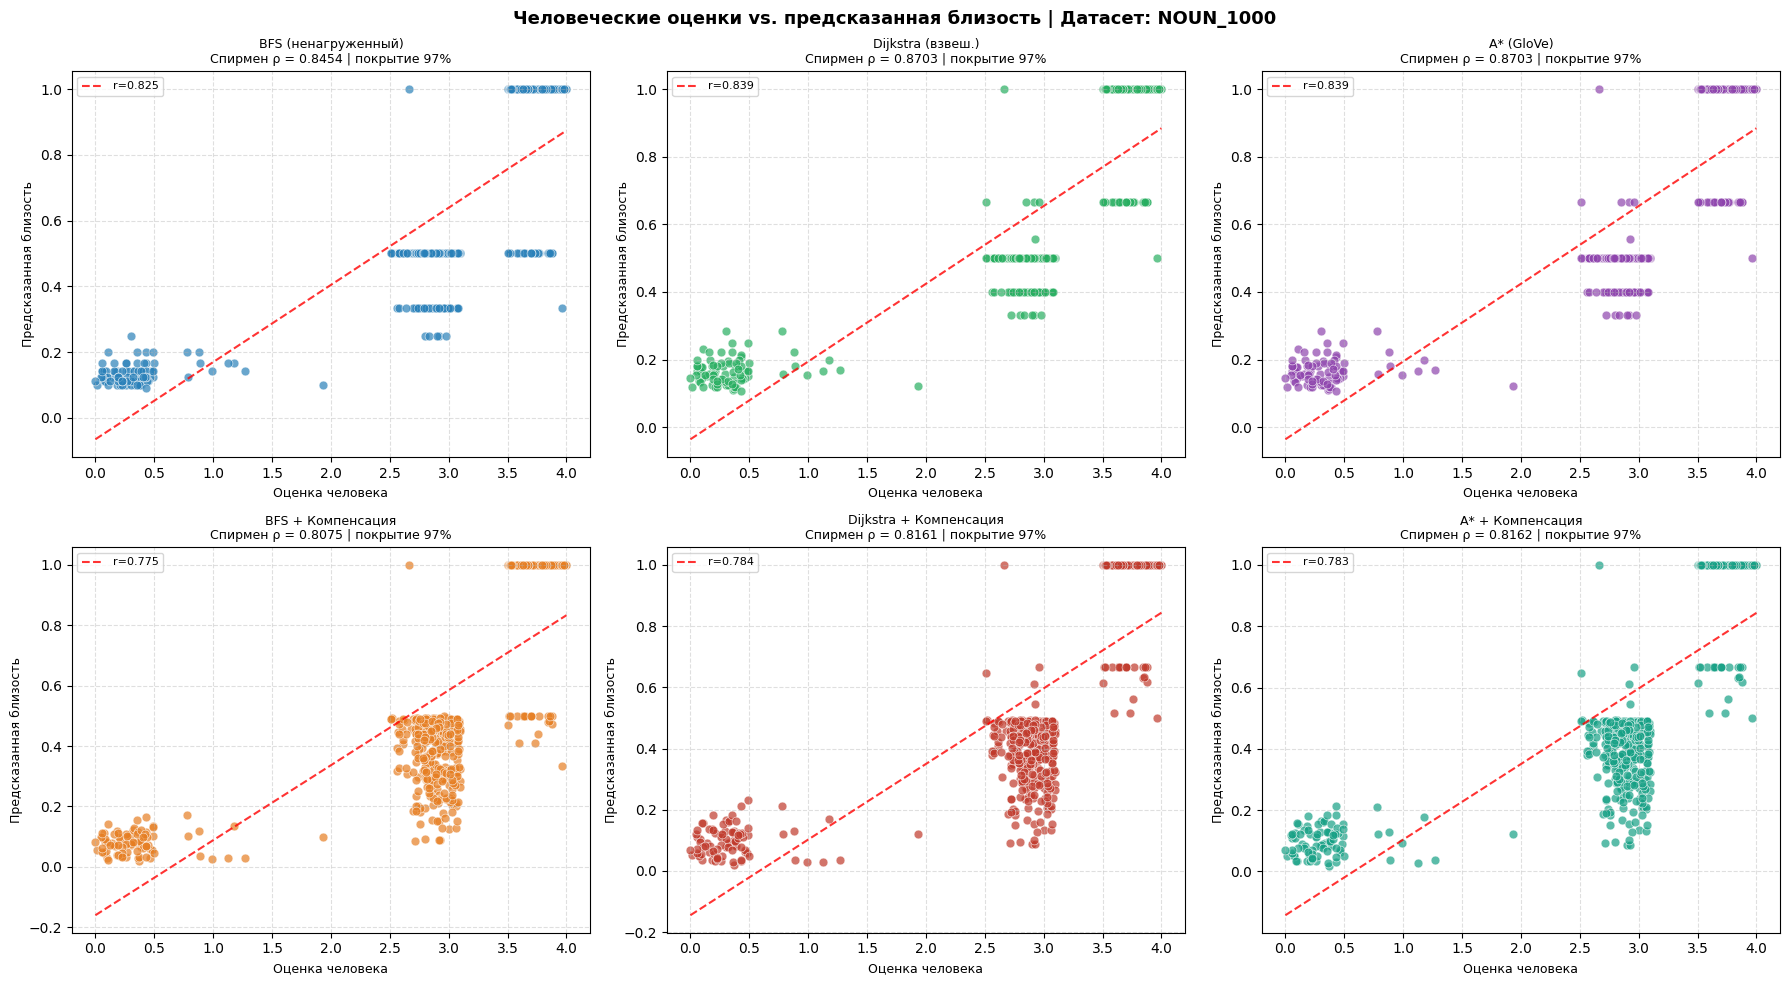

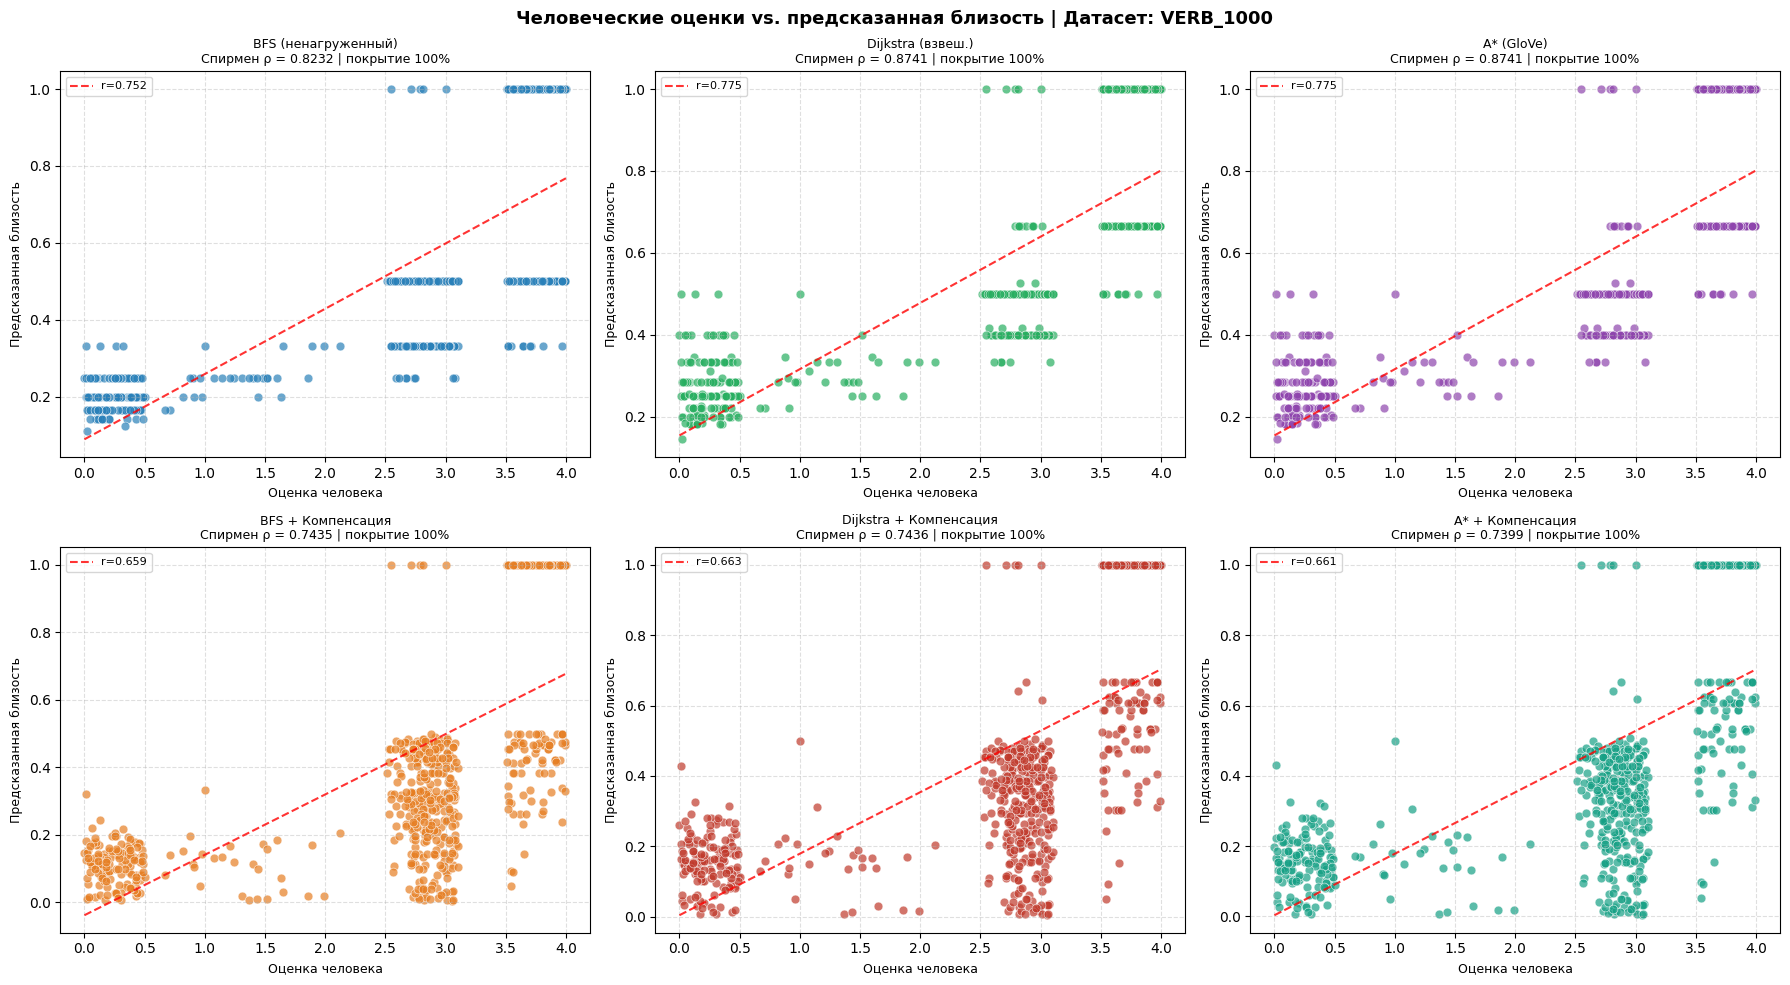

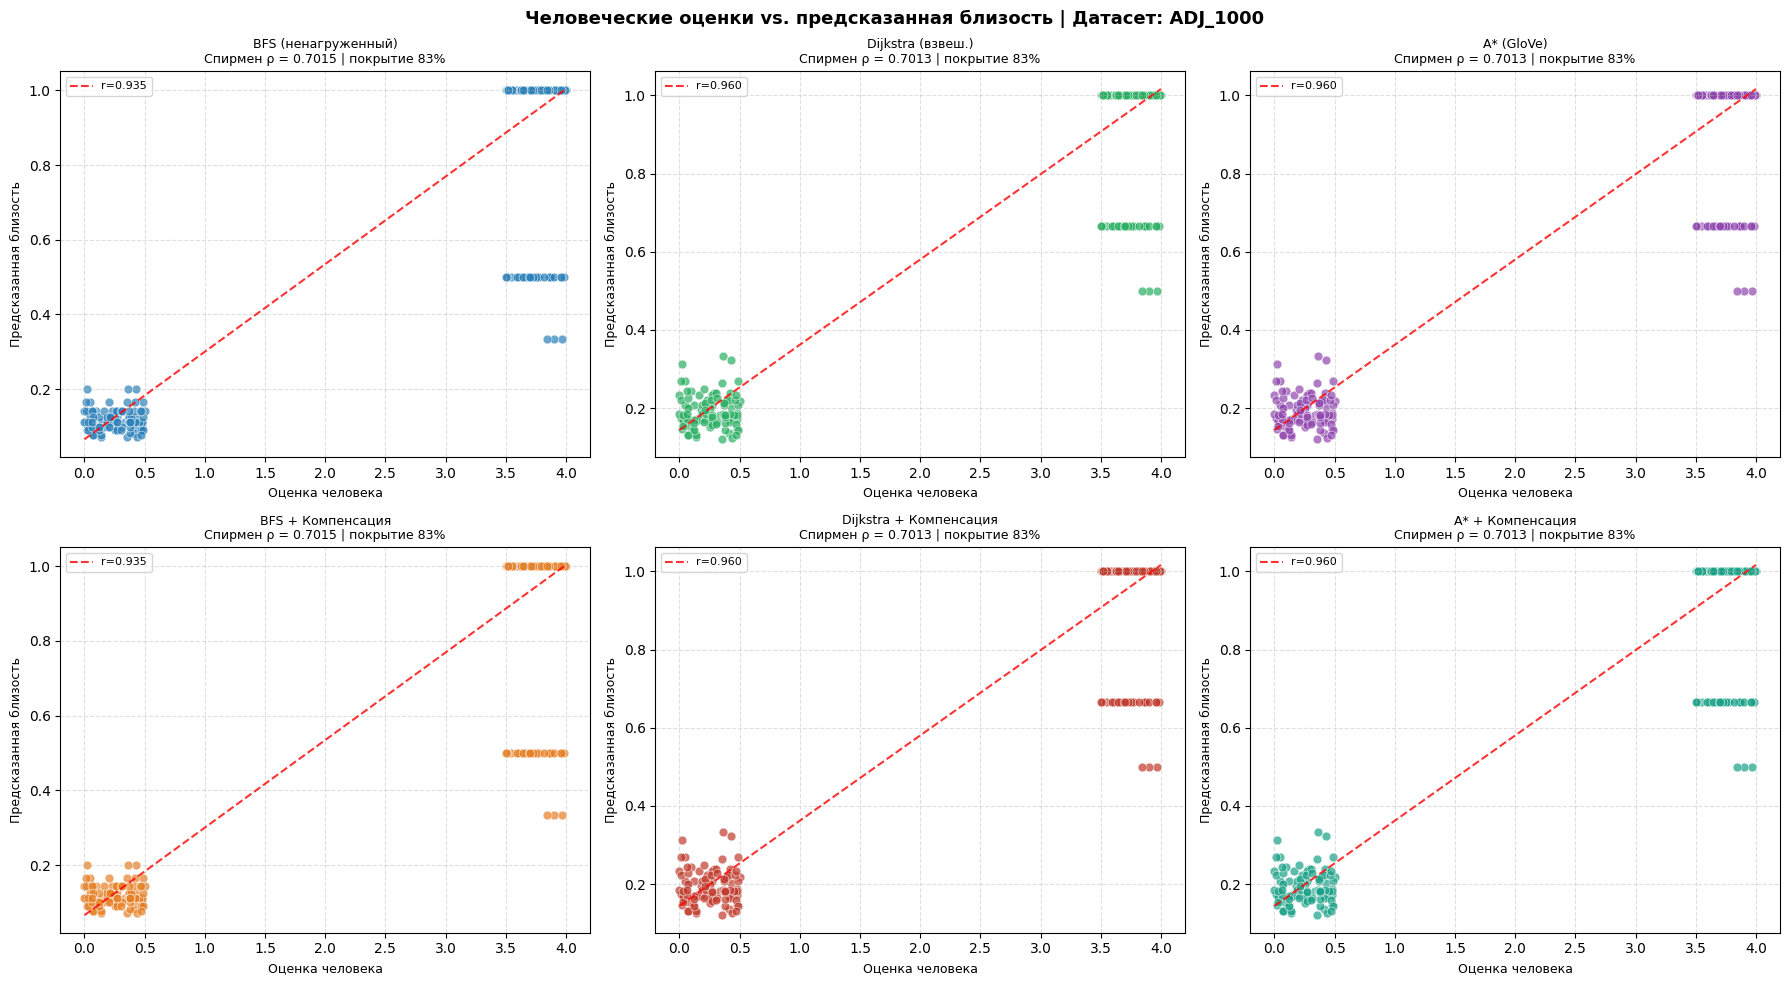

In [ ]:
# ── ЯЧЕЙКА 13: Scatter-plots (человек vs модель) ──────────────────────────────

def plot_scatter(
    results_dict: Dict,
    dataset_name: str,
):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(
        f"Человеческие оценки vs. предсказанная близость | Датасет: {dataset_name}",
        fontsize=13, fontweight="bold",
    )
    colors = ["#2980B9", "#27AE60", "#8E44AD", "#E67E22", "#C0392B", "#16A085"]

    for idx, (key, label, _) in enumerate(METHODS):
        ax = axes.flatten()[idx]
        res = results_dict[key]
        h_vals = np.array(res["human"])
        p_vals = np.array(res["predicted"])
        mask = p_vals > 0
        h_v, p_v = h_vals[mask], p_vals[mask]

        ax.scatter(h_v, p_v, c=colors[idx], alpha=0.7, s=40,
                   edgecolors="white", linewidths=0.5)

        if len(h_v) >= 3:
            slope, intercept, r, *_ = scipy_stats.linregress(h_v, p_v)
            x_line = np.linspace(h_v.min(), h_v.max(), 100)
            ax.plot(x_line, slope * x_line + intercept,
                    "r--", lw=1.5, alpha=0.8, label=f"r={r:.3f}")
            ax.legend(fontsize=8)

        ax.set_xlabel("Оценка человека", fontsize=9)
        ax.set_ylabel("Предсказанная близость", fontsize=9)
        ax.set_title(
            f"{label}\nСпирмен ρ = {res['spearman']:.4f} | "
            f"покрытие {res['coverage']:.0%}",
            fontsize=9,
        )
        ax.grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()
    fname = f"scatter_{dataset_name.lower().replace(' ', '_')}.png"
    plt.savefig(fname, dpi=120, bbox_inches="tight")
    plt.show()


# Scatter для всех датасетов
for ds_name, ds_results in [
    ("MC30",       results_mc30),
    ("RG65",       results_rg65),
    ("VERB_PAIRS", results_verb),
    ("ADJ_PAIRS",  results_adj),
    ("NOUN_1000",  results_noun1000),
    ("VERB_1000",  results_verb1000),
    ("ADJ_1000",   results_adj1000),
]:
    plot_scatter(ds_results, ds_name)

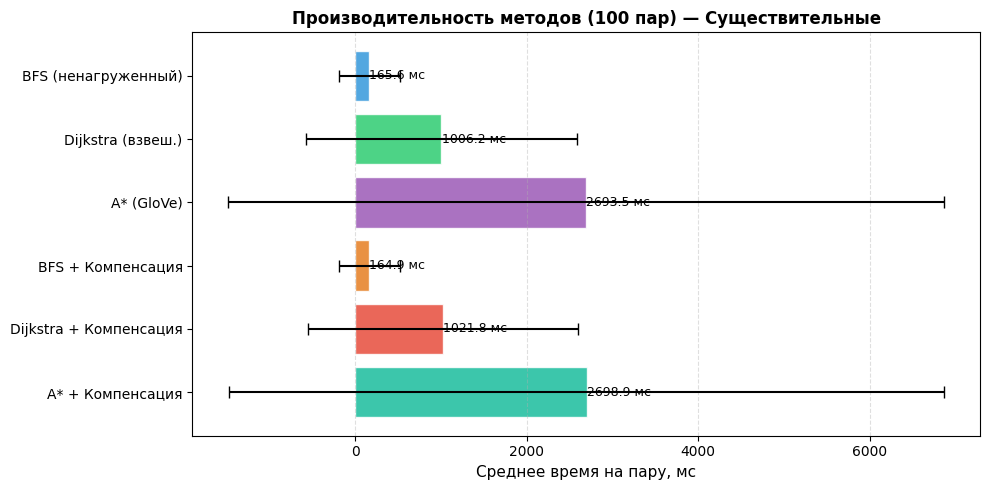

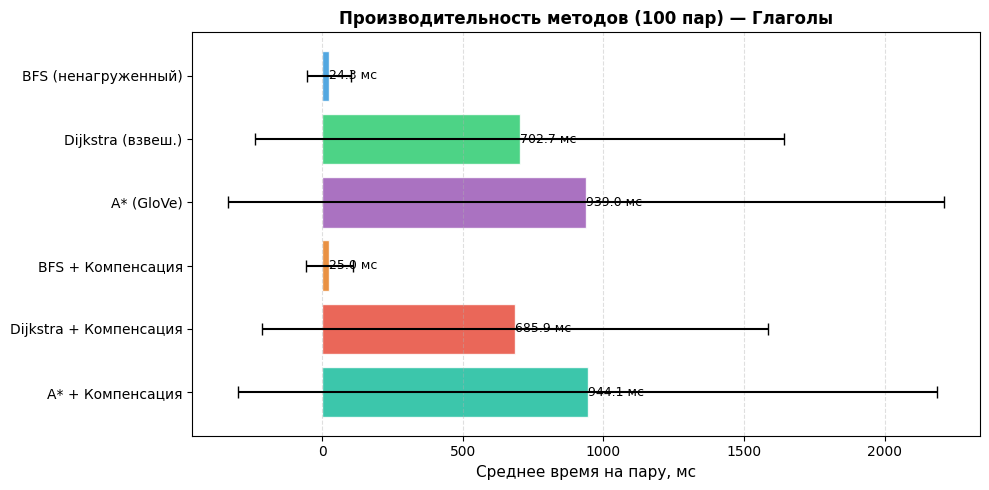

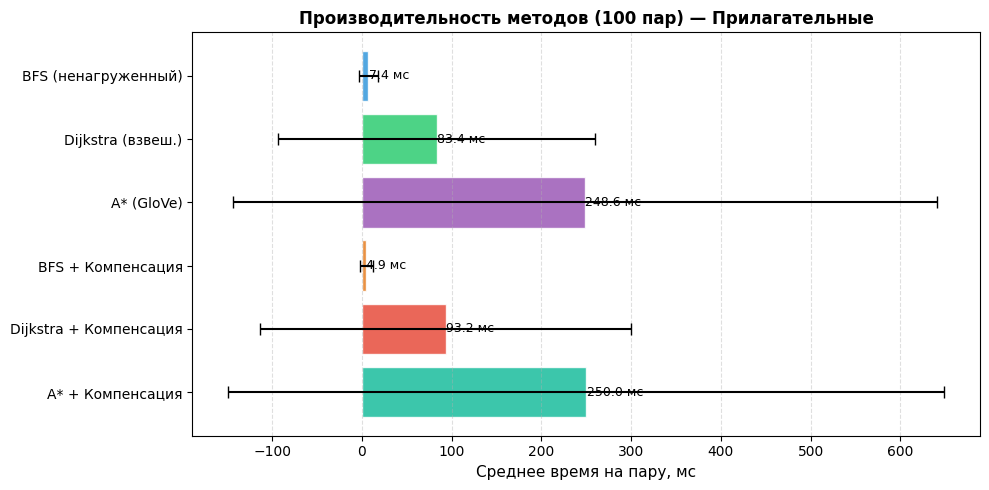

In [ ]:
# ── ЯЧЕЙКА 14: Гистограммы производительности ────────────────────────────────

def plot_timing_bar(
    timing_results: Dict,
    title_suffix: str = "",
    save_fname: str = "timing_comparison.png",
):
    methods_order  = [k for k, *_ in METHODS]
    labels_ordered = [timing_results[k]["name"] for k in methods_order]
    means          = [timing_results[k]["mean_ms"] for k in methods_order]
    stds           = [timing_results[k]["std_ms"]  for k in methods_order]
    colors = ["#3498DB", "#2ECC71", "#9B59B6", "#E67E22", "#E74C3C", "#1ABC9C"]

    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.barh(labels_ordered, means, xerr=stds, color=colors,
                   alpha=0.85, edgecolor="white", capsize=4)

    for bar, val in zip(bars, means):
        ax.text(val + 0.3, bar.get_y() + bar.get_height() / 2,
                f"{val:.1f} мс", va="center", ha="left", fontsize=9)

    ax.set_xlabel("Среднее время на пару, мс", fontsize=11)
    ax.set_title(
        f"Производительность методов (100 пар) {title_suffix}",
        fontsize=12, fontweight="bold"
    )
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig(save_fname, dpi=120, bbox_inches="tight")
    plt.show()


plot_timing_bar(timing_n, "— Существительные", "timing_nouns.png")
plot_timing_bar(timing_v, "— Глаголы",         "timing_verbs.png")
plot_timing_bar(timing_a, "— Прилагательные",  "timing_adjs.png")

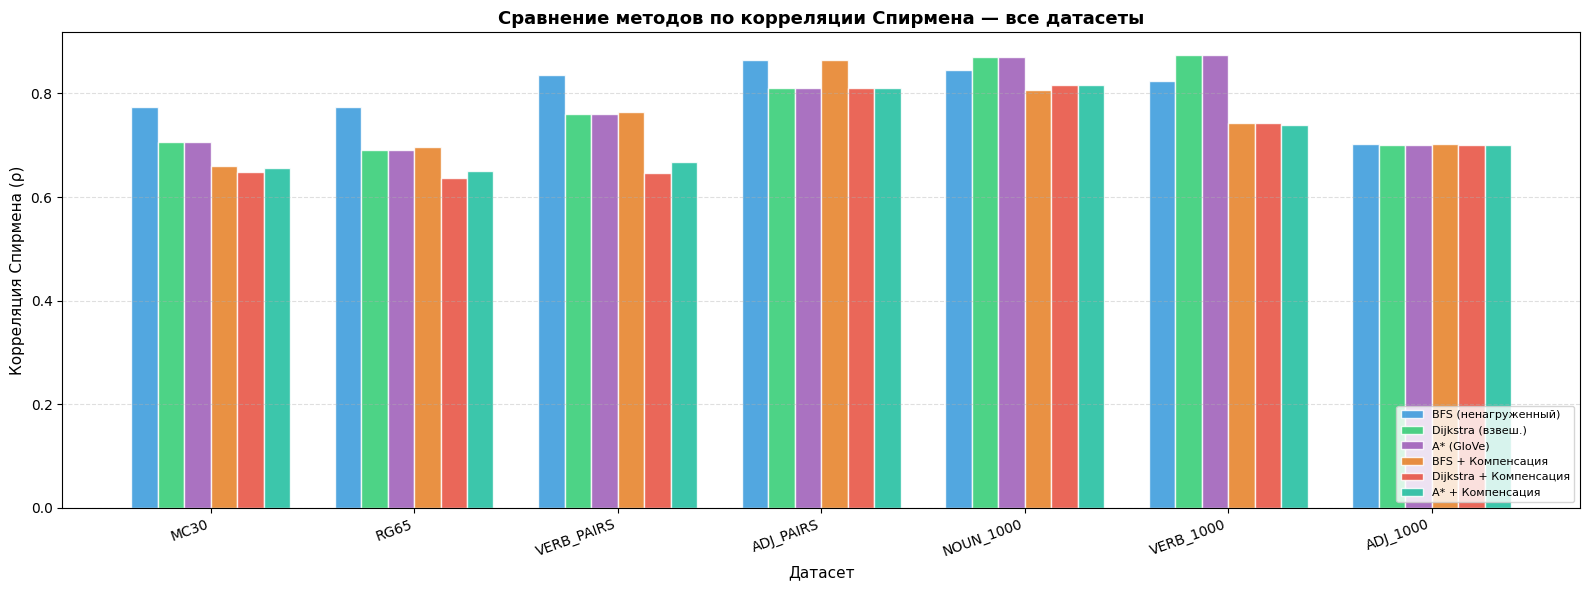

In [ ]:
# ── ЯЧЕЙКА 15: Сравнительный bar-chart корреляций по части речи ───────────────
# Наглядное сравнение лучшего метода на каждом датасете

def plot_correlation_comparison(all_results_map: Dict[str, Dict]):
    """
    Группированная bar-диаграмма: для каждого датасета показывает
    корреляцию Спирмена по всем 6 методам.
    """
    datasets   = list(all_results_map.keys())
    method_keys = [k for k, *_ in METHODS]
    method_lbl  = [lbl for _, lbl, _ in METHODS]

    x = np.arange(len(datasets))
    width = 0.13
    colors = ["#3498DB", "#2ECC71", "#9B59B6", "#E67E22", "#E74C3C", "#1ABC9C"]

    fig, ax = plt.subplots(figsize=(16, 6))

    for i, (key, lbl) in enumerate(zip(method_keys, method_lbl)):
        values = [
            all_results_map[ds].get(key, {}).get("spearman", 0.0)
            for ds in datasets
        ]
        offset = (i - len(method_keys) / 2 + 0.5) * width
        bars = ax.bar(x + offset, values, width, label=lbl,
                      color=colors[i], alpha=0.85, edgecolor="white")

    ax.set_xlabel("Датасет", fontsize=11)
    ax.set_ylabel("Корреляция Спирмена (ρ)", fontsize=11)
    ax.set_title(
        "Сравнение методов по корреляции Спирмена — все датасеты",
        fontsize=13, fontweight="bold"
    )
    ax.set_xticks(x)
    ax.set_xticklabels(datasets, rotation=20, ha="right")
    ax.legend(fontsize=8, loc="lower right")
    ax.axhline(0, color="black", linewidth=0.7, linestyle="--", alpha=0.5)
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig("correlation_comparison_all.png", dpi=120, bbox_inches="tight")
    plt.show()


plot_correlation_comparison(all_results_map)

In [ ]:
# ── ЯЧЕЙКА 16: Топ-5 ближайших понятий ───────────────────────────────────────

def demo_top5(
    words: List[str],
    sg: SemanticGraph,
    method: str = "dijkstra_compensated",
    pos_label: str = "",
):
    label = pos_label or sg.pos
    for word in words:
        print(f"\n{'─'*60}")
        print(f"  [{label}] Топ-5 ближайших к «{word}» (метод: {method})")
        print(f"{'─'*60}")
        results = sg.top5_nearest(word, method=method)
        if not results:
            print("  ⚠ Результаты не найдены")
            continue
        for i, r in enumerate(results, 1):
            print(
                f"  {i}. {r['synset']:<28}  sim={r['similarity']:.4f}  "
                f"dist={r['distance']:.4f}\n"
                f"     {r['definition']}"
            )


# Существительные
demo_top5(["car", "journey", "bird"], sg_n,
          method="dijkstra_compensated", pos_label="NOUN")

# Глаголы
demo_top5(["run", "speak", "build"], sg_v,
          method="dijkstra_compensated", pos_label="VERB")

# Прилагательные
demo_top5(["fast", "big", "happy"], sg_a,
          method="dijkstra_compensated", pos_label="ADJ")


────────────────────────────────────────────────────────────
  [NOUN] Топ-5 ближайших к «car» (метод: dijkstra_compensated)
────────────────────────────────────────────────────────────
  1. car.n.04                      sim=0.4034  dist=1.4789
     where passengers ride up and down
  2. car.n.03                      sim=0.4034  dist=1.4789
     the compartment that is suspended from an airship and that carries per
  3. cable_car.n.01                sim=0.4034  dist=1.4789
     a conveyance for passengers or freight on a cable railway
  4. machine.n.04                  sim=0.3838  dist=1.6053
     a device for overcoming resistance at one point by applying force at s
  5. gasoline_engine.n.01          sim=0.3741  dist=1.6727
     an internal-combustion engine that burns gasoline; most automobiles ar

────────────────────────────────────────────────────────────
  [NOUN] Топ-5 ближайших к «journey» (метод: dijkstra_compensated)
────────────────────────────────────────────────────────────

In [ ]:
# ── ЯЧЕЙКА 17: Unit-тесты (расширенные) ──────────────────────────────────────

def run_unit_tests(
    sg_n: SemanticGraph,
    sg_v: SemanticGraph,
    sg_a: SemanticGraph,
):
    """
    Расширенные unit-тесты: покрывают существительные, глаголы и прилагательные.
    """
    passed = 0
    failed = 0

    def check(cond, msg):
        nonlocal passed, failed
        if cond:
            print(f"  ✓ {msg}")
            passed += 1
        else:
            print(f"  ✗ FAIL: {msg}")
            failed += 1

    print("\n" + "═" * 60)
    print("  UNIT-ТЕСТЫ")
    print("═" * 60)

    # ── T1–T4: Структура графов ───────────────────────────────────────────────
    print("\n[T1–T4] Структура графов")
    check("car.n.01"    in sg_n.G, "T1a: car.n.01 в графе сущ.")
    check("entity.n.01" in sg_n.G, "T1b: entity.n.01 в графе сущ.")
    check(sg_n.G.number_of_nodes() > 50_000, "T1c: >50k узлов в граф сущ.")
    check("run.v.01"    in sg_v.G, "T2a: run.v.01 в графе глаг.")
    check(sg_v.G.number_of_nodes() > 5_000,  "T2b: >5k узлов в граф глаг.")
    check("fast.a.01"   in sg_a.G, "T3a: fast.a.01 в графе прил.")
    check(sg_a.G.number_of_nodes() > 5_000,  "T3b: >5k узлов в граф прил.")
    check(sg_n.pos == "n" and sg_v.pos == "v" and sg_a.pos == "a",
          "T4: pos атрибуты корректны")

    # ── T5–T7: Глубины и плотности ────────────────────────────────────────────
    print("\n[T5–T7] Глубины и плотности")
    d_entity = sg_n.depth("entity.n.01")
    d_car    = sg_n.depth("car.n.01")
    check(d_entity == 0,         f"T5a: глубина entity.n.01 = 0 (получено {d_entity})")
    check(d_car > d_entity,      f"T5b: глубина car > entity ({d_car} > {d_entity})")
    dens = sg_n.density("entity.n.01")
    check(dens >= 0,             f"T6: плотность entity ≥ 0 (получено {dens})")
    d_run = sg_v.depth("run.v.01")
    check(d_run >= 0,            f"T7: глубина run.v.01 ≥ 0 (получено {d_run})")

    # ── T8–T10: BFS и Dijkstra ────────────────────────────────────────────────
    print("\n[T8–T10] BFS / Dijkstra")
    d_same, p_same = sg_n.bfs_path("car.n.01", "car.n.01")
    check(d_same == 0.0 and p_same == ["car.n.01"],
          f"T8: BFS(x,x)=0  path=[x]")
    d_dijk, _ = sg_n.dijkstra_path("car.n.01", "car.n.01")
    check(d_dijk == 0.0, "T9: Dijkstra(x,x)=0")
    # Глагол: run и sprint должны быть ближе, чем run и sleep
    sim_rv = compute_pair_similarity("run",  "sprint", sg_v, "dijkstra")
    sim_rs = compute_pair_similarity("run",  "sleep",  sg_v, "dijkstra")
    check(sim_rv >= sim_rs or sim_rv > 0,
          f"T10: sim(run,sprint)={sim_rv:.4f} ≥ sim(run,sleep)={sim_rs:.4f}")

    # ── T11–T13: Семантические близости ──────────────────────────────────────
    print("\n[T11–T13] Семантические близости")
    sim_close = compute_pair_similarity("car",   "automobile", sg_n, "dijkstra")
    sim_far   = compute_pair_similarity("car",   "tree",       sg_n, "dijkstra")
    check(sim_close > sim_far,
          f"T11: sim(car,automobile)={sim_close:.4f} > sim(car,tree)={sim_far:.4f}")

    sim_fast_quick = compute_pair_similarity("fast", "quick", sg_a, "dijkstra")
    sim_fast_dark  = compute_pair_similarity("fast", "dark",  sg_a, "dijkstra")
    check(sim_fast_quick >= sim_fast_dark,
          f"T12: sim(fast,quick)={sim_fast_quick:.4f} ≥ sim(fast,dark)={sim_fast_dark:.4f}")

    for w1, w2, _ in MC30[:5]:
        s = compute_pair_similarity(w1, w2, sg_n, "dijkstra_compensated")
        check(0.0 <= s <= 1.0, f"T13: sim({w1},{w2})={s:.4f} ∈ [0,1]")

    # ── T14: Компенсация плотности ────────────────────────────────────────────
    print("\n[T14] Компенсация плотности")
    d_base, path = sg_n.dijkstra_path("car.n.01", "entity.n.01")
    d_comp = sg_n._density_compensated_distance(path, d_base)
    check(d_comp >= d_base,
          f"T14: компенсация ≥ базовой ({d_base:.3f} → {d_comp:.3f})")

    # ── T15: A*(h=0) ≡ Dijkstra ───────────────────────────────────────────────
    print("\n[T15] A*(h=0) ≡ Dijkstra")
    na, nb = "car.n.01", "vehicle.n.01"
    if na in sg_n.G and nb in sg_n.G:
        d_d, _ = sg_n.dijkstra_path(na, nb)
        d_a, _ = sg_n.astar_path(na, nb, lambda n, t: 0.0)
        check(abs(d_a - d_d) < 1e-6,
              f"T15: A*(h=0)={d_a:.3f} ≡ Dijkstra={d_d:.3f}")

    # ── T16: Top-5 не пуст ───────────────────────────────────────────────────
    print("\n[T16] Top-5 nearest")
    for word, sg_ in [("car", sg_n), ("run", sg_v), ("fast", sg_a)]:
        top5 = sg_.top5_nearest(word)
        check(len(top5) > 0, f"T16: top5_nearest('{word}', pos={sg_.pos}) не пуст")

    # ── T17: Несвязанные слова → очень малая близость ─────────────────────────
    print("\n[T17] Несвязанные слова")
    s_unrel = compute_pair_similarity("car", "democracy", sg_n, "bfs")
    check(s_unrel < 0.5, f"T17: sim(car, democracy)={s_unrel:.4f} < 0.5")

    # ── Итог ──────────────────────────────────────────────────────────────────
    print(f"\n{'═'*60}")
    print(f"  Итог: {passed} прошли, {failed} провалились (из {passed+failed} тестов)")
    print(f"{'═'*60}")


run_unit_tests(sg_n, sg_v, sg_a)


════════════════════════════════════════════════════════════
  UNIT-ТЕСТЫ
════════════════════════════════════════════════════════════

[T1–T4] Структура графов
  ✓ T1a: car.n.01 в графе сущ.
  ✓ T1b: entity.n.01 в графе сущ.
  ✓ T1c: >50k узлов в граф сущ.
  ✓ T2a: run.v.01 в графе глаг.
  ✓ T2b: >5k узлов в граф глаг.
  ✓ T3a: fast.a.01 в графе прил.
  ✓ T3b: >5k узлов в граф прил.
  ✓ T4: pos атрибуты корректны

[T5–T7] Глубины и плотности
  ✓ T5a: глубина entity.n.01 = 0 (получено 0)
  ✓ T5b: глубина car > entity (10 > 0)
  ✓ T6: плотность entity ≥ 0 (получено 3)
  ✓ T7: глубина run.v.01 ≥ 0 (получено 2)

[T8–T10] BFS / Dijkstra
  ✓ T8: BFS(x,x)=0  path=[x]
  ✓ T9: Dijkstra(x,x)=0
  ✓ T10: sim(run,sprint)=0.5000 ≥ sim(run,sleep)=0.2857

[T11–T13] Семантические близости
  ✓ T11: sim(car,automobile)=1.0000 > sim(car,tree)=0.3226
  ✓ T12: sim(fast,quick)=0.6667 ≥ sim(fast,dark)=0.2778
  ✓ T13: sim(car,automobile)=1.0000 ∈ [0,1]
  ✓ T13: sim(journey,voyage)=0.3893 ∈ [0,1]
  ✓ T13: sim

Тесты для проверки синсетов и дистанций в графе

In [ ]:
bank_synsets = [s for s in wn.all_synsets('n') for l in s.lemmas() if l.name() == "bank"]
print(f"Синсетов с леммой 'bank': {len(bank_synsets)}")
print([s.name() for s in bank_synsets])
print(sg.G.has_edge("bank.n.01", "bank.n.03"))  # True

In [ ]:
def dist_by_synset(synset1: str, synset2: str, sg, method="bfs"):
    """Выводит семантическую дистанцию между двумя синсетами."""

    if not sg.G.has_node(synset1) or not sg.G.has_node(synset2):
        print(f"Синсет '{synset1}' или '{synset2}' не найден в графе")
        return None

    d = sg.semantic_distance(synset1, synset2, method=method)
    print(f"{synset1}, {synset2} : {d:.4f}")


# Примеры
dist_by_synset("bank.n.01", "bank.n.03", sg, method="dijkstra")
dist_by_synset("car.n.01", "motor_vehicle.n.01", sg, method="dijkstra")
dist_by_synset("car.n.01", "cab.n.03", sg, method="dijkstra")
dist_by_synset("car.n.01", "car_window.n.01", sg, method="dijkstra")


# find function
for synset in wn.synsets('bank', pos='n'):
    print()
    print(f"--- {synset.name()} ---")
    print(synset.lemmas())
    print(synset.examples())
    print(f"  гиперонимы:    {synset.hypernyms()}")
    print(f"  меронимы (part): {synset.part_meronyms()}")
    print(f"  меронимы (member): {synset.member_meronyms()}")
    print(f"  меронимы (substance): {synset.substance_meronyms()}")
    print()
